# TriMAQs report figures

Figures for the “Trends in Exposure to Air Pollutants from Marcellus and Utica Shale Development (TriMAQs)” report by Gernand et al.

Run the setup and plotting-functions cells first, then run each figure cell in order. Each figure appears below its code cell and is also saved as a high-resolution PNG. Captions and plotted-data tables are saved with the figures. The notebook reads existing data and does not run the models.

For another computer, set the data and results roots in the first cell or through `TRIMAQS_DATA_ROOT` and `TRIMAQS_RESULTS_ROOT`. The plotting code is included in this notebook; no companion Python plotting file is needed.

Saved figure outputs are included for viewing. They were generated from the complete study analysis files. Re-running every section also requires the inventory, statistics and other inputs named in that section; the compact public archive contains UOGD-only outputs and excludes ML predictions, tier-specific concentrations and statistics. Set the data and results roots before running on another computer.


## 1. Data and output folders

The roots below select the current HPC data when available. Paths within the dataset are relative to those roots. For the published archive, place the figure statistics under `inputs/figure_support/statistics/` or adjust `STATS_ROOT` here.

In [32]:
from pathlib import Path
import os

# Set these roots for your computer or shared data archive.
# On the current HPC, the existing folders below are selected automatically.
hpc_data=Path.cwd()/'TriMAQs_data_public'
hpc_results=hpc_data/'outputs'
DATA_ROOT=Path(os.environ.get('TRIMAQS_DATA_ROOT', str(hpc_data if hpc_data.is_dir() else Path.cwd()/'TriMAQs_data'))).expanduser()
RESULTS_ROOT=Path(os.environ.get('TRIMAQS_RESULTS_ROOT', str(hpc_results if hpc_results.is_dir() else DATA_ROOT/'outputs'))).expanduser()
STATS_ROOT=RESULTS_ROOT/'report_review'
if not STATS_ROOT.is_dir():
    STATS_ROOT=DATA_ROOT/'inputs/figure_support/statistics'

CONCENTRATION_DIR=RESULTS_ROOT/'concentrations'
CONTRIBUTION_DIR=RESULTS_ROOT/'source_apportionment'
if not CONTRIBUTION_DIR.is_dir():
    CONTRIBUTION_DIR=RESULTS_ROOT/'source_contributions'
EXPOSURE_DIR=STATS_ROOT/'exposure'
if not EXPOSURE_DIR.is_dir():
    EXPOSURE_DIR=RESULTS_ROOT/'exposure'
REVIEW_DIR=STATS_ROOT/'concentrations'
PROCESSED=RESULTS_ROOT
BOUNDARY_FILE=DATA_ROOT/'inputs/supporting/boundary/study_boundary.shp'
FIGURE_DIR=RESULTS_ROOT/'figures/report_current'

YEARS=list(range(2004,2024))
SOURCE='UOGD'
DPI=600
SAVE_PDF=False
SHOW_FIGURES=True
DRAW_BOUNDARY=True
MIN_VALID_DAYS=1
SA_STATISTIC='annual_mean_fraction'
CONCENTRATION_RANGES={'NO2':(1e-4,25),'PM25':(2e-4,2),'VOC':(5e-4,500),'SO2':(1e-5,5)}
# Source/ML ratios: 0.40 means 40%. These limits affect colors only.
CONTRIBUTION_RANGES={'NO2':(0,1.3),'PM25':(0,.03),'SO2':(0,.08)}
SUPPLEMENTARY=False
print('Data:',DATA_ROOT)
print('Results:',RESULTS_ROOT)
print('Statistics:',STATS_ROOT)
print('Figures:',FIGURE_DIR)


Data: /storage/group/jmg64/default/Sharable data/TriMAQs_data
Results: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed
Statistics: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/report_review
Figures: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current


## 2. Plotting functions

This cell defines the shared readers and plotting functions. The maps retain the original palette, square markers, county outlines and display-only concentration floors. Color scales remain fixed across years. Data used for statistics are not floored or capped.
Annual map arrays are cached in `RESULTS_ROOT/figure_cache/annual_maps` (one compressed file per year and data type). The first read builds the cache; later plots reuse it. Changes to colors, limits and valid-day settings do not require rebuilding. Changed source files refresh automatically. The cache is disposable and can be recreated from the NetCDF files.


In [3]:
import json, calendar, traceback
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from netCDF4 import Dataset
from IPython.display import display, Markdown

get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams['figure.dpi']=100  # Inline preview; saved files use DPI above.
LABELS={'NO2':r'NO$_2$','PM25':r'PM$_{2.5}$','VOC':'VOCs','SO2':r'SO$_2$'}
UNITS={'NO2':'ppb','SO2':'ppb','PM25':'ug/m3','VOC':'ug/m3'}
PLOT_UNITS={'NO2':'ppb','SO2':'ppb','PM25':r'$\mu$g m$^{-3}$','VOC':r'$\mu$g m$^{-3}$'}
CONCENTRATION_NUMBERS={'NO2':13,'PM25':14,'VOC':15,'SO2':16}
CONTRIBUTION_NUMBERS={'NO2':36,'PM25':37,'SO2':38}
FIGURE_RECORDS=[]
CAPTIONS=[]

def concentration_file(year):return CONCENTRATION_DIR/f'aermod_daily_conc_{year}.nc'

def contribution_file(year):return CONTRIBUTION_DIR/f'uogd_source_apportionment_{year}.nc'

def read_values(var):return np.ma.filled(np.ma.asarray(var[:], dtype=float),np.nan)

def annual_layer(year,pol,kind='concentration'):
    """Read compact annual arrays; reuse the scratch cache when source data match."""
    path=concentration_file(year) if kind=='concentration' else contribution_file(year)
    stat=path.stat()
    signature=json.dumps([str(path.resolve()),stat.st_size,stat.st_mtime_ns,SOURCE,1])
    cache_dir=PROCESSED/'figure_cache'/'annual_maps'
    cache_dir.mkdir(parents=True,exist_ok=True)
    cache=cache_dir/f'{kind}_{year}_{SOURCE}.npz'
    bundle=None
    if cache.is_file():
        try:
            with np.load(cache,allow_pickle=False) as stored:
                if str(stored['signature'].item())==signature:
                    bundle={key:stored[key] for key in stored.files}
        except (OSError,ValueError,EOFError):
            bundle=None
    if bundle is None:
        with Dataset(path) as ds:
            sources=list(ds['source'][:])
            if sources not in [['Tier_1','Tier_2','UOGD'],['UOGD']]:raise ValueError('Unexpected source labels')
            bundle=dict(signature=np.array(signature),mask=read_values(ds['study_mask']).astype(bool),lat=read_values(ds['lat']),lon=read_values(ds['lon']))
            for pollutant in (LABELS if kind=='concentration' else CONTRIBUTION_NUMBERS):
                names=[pollutant+'_annual'] if kind=='concentration' else [pollutant+'_annual_mean_fraction',pollutant+'_annual_ratio']
                for name in names:
                    if kind=='concentration' and ds[name].units!=UNITS[pollutant]:raise ValueError('Unexpected concentration units')
                    bundle[name]=np.ma.filled(np.ma.asarray(ds[name][sources.index(SOURCE)],dtype=float),np.nan)
                if kind!='concentration':bundle[pollutant+'_valid_days']=read_values(ds[pollutant+'_valid_days'])
        temporary=cache.with_name(cache.name+f'.{os.getpid()}.tmp')
        try:
            with temporary.open('wb') as handle:np.savez_compressed(handle,**bundle)
            os.replace(temporary,cache)
        finally:
            temporary.unlink(missing_ok=True)
    name=pol+'_annual' if kind=='concentration' else pol+'_'+SA_STATISTIC
    values=bundle[name]
    if kind!='concentration':values=np.where(bundle[pol+'_valid_days']>=MIN_VALID_DAYS,values,np.nan)
    grid={key:bundle[key] for key in ['mask','lat','lon']}
    return np.where(grid['mask'],np.nan,values),grid



def preflight():
    required=[concentration_file(y) for y in YEARS]+[contribution_file(y) for y in YEARS]
    required += [EXPOSURE_DIR/n for n in ['annual_exposure.csv','Population_Above_Limit_Annual.csv','Population_Above_Limit_Daily.csv','RRR_annual_allPollutants.csv']]
    required += [EXPOSURE_DIR/f'RRR_dailyAnnual_{p}.csv' for p in ['NO2','PM2.5','SO2']]
    required += [REVIEW_DIR/'daily.csv',REVIEW_DIR/'annual.csv',STATS_ROOT/'source_contributions/fractions.csv',BOUNDARY_FILE]
    missing=[str(p) for p in required if not p.is_file()]
    if missing:raise FileNotFoundError('Required figure inputs missing:\n'+'\n'.join(missing))
    for pol in LABELS:
        for year in YEARS:annual_layer(year,pol)
    FIGURE_DIR.mkdir(parents=True,exist_ok=True)
    print('Inputs checked. Figures:',FIGURE_DIR,flush=True)

def daily_spatial_summary():
    table=pd.read_csv(REVIEW_DIR/'daily.csv',parse_dates=['date'])
    table=table[table.source.eq(SOURCE)&table.year.isin(YEARS)].copy()
    table['pollutant']=table.pollutant.replace({'PM2.5':'PM25'})
    table=table.rename(columns={'spatial_mean':'mean_concentration'})
    expected=pd.DatetimeIndex(np.concatenate([pd.date_range(f'{y}-01-01',f'{y}-12-31').values for y in YEARS]))
    for pol in LABELS:
        q=table[table.pollutant.eq(pol)].sort_values('date')
        if not pd.DatetimeIndex(q.date).equals(expected) or q.units.ne(UNITS[pol]).any():raise ValueError('Daily statistics calendar/units differ: '+pol)
    return table

def contribution_coverage():
    table=pd.read_csv(STATS_ROOT/'source_contributions/fractions.csv')
    table=table[table.source.eq(SOURCE)&table.statistic.eq(SA_STATISTIC)&table.year.isin(YEARS)]
    table.to_csv(FIGURE_DIR/'source_contribution_coverage.csv',index=False)
    return table

def regional_emissions():
    data={};tokens={'NOX':'nox','PM2.5':'PM25','VOC':'VOC','SO2':'so2'}
    for pol,token in tokens.items():
        industrial=pd.read_csv(DATA_ROOT/f'inputs/emissions/other_industry/{pol}_interpolated_emission.csv')
        pieces=[]
        for year in YEARS:
            file=DATA_ROOT/f'inputs/emissions/power_plants/Daily {year}/formatted-daily-{year}-{token}.csv'
            frame=pd.read_csv(file);dates=pd.date_range(f'{year}-01-01',f'{year}-12-31');fields=[str(d.date()) for d in dates]
            values=frame[fields].apply(pd.to_numeric,errors='raise')
            if values.isna().any().any() or (values<0).any().any():raise ValueError('Invalid power-plant mass')
            # Same explicit raw-file unit interpretation as the power-plant job.
            power=values.sum(axis=0).to_numpy()*.90718474
            annual=pd.to_numeric(industrial[f'{year}_emission'],errors='raise')
            if annual.isna().any() or (annual<0).any():raise ValueError('Invalid industrial mass')
            pieces.append(pd.DataFrame(dict(date=dates,power=power,industrial=annual.sum()/len(dates))))
        data[pol]=pd.concat(pieces)
    fig,axes=plt.subplots(4,1,figsize=(12,11.2),sharex=True,gridspec_kw={'hspace':0})
    fig.suptitle('Non-UOGD industrial emissions (metric tonnes/day)',fontsize=18,y=.925)
    labels={'NOX':r'NO$_x$','PM2.5':r'PM$_{2.5}$','VOC':'VOCs','SO2':r'SO$_2$'}
    for i,(ax,pol) in enumerate(zip(axes,data)):
        q=data[pol];ax.stackplot(q.date,q.power,q.industrial,labels=['Power plants','Other industry'],colors=['#315FA3','black'],alpha=.9)
        ax.text(.5,.95,f'({chr(97+i)}) {labels[pol]}',transform=ax.transAxes,ha='center',va='top',fontsize=14,fontweight='bold')
        ax.set_ylabel('Metric tonnes/day',fontsize=11);ax.grid(axis='y',ls='--',alpha=.4)
        q.assign(pollutant=pol).to_csv(FIGURE_DIR/f'Figure_07_{pol}_data.csv',index=False)
    axes[0].legend(loc='upper right',frameon=False);axes[-1].set_xlabel('Year')
    axes[-1].set_xlim(pd.Timestamp('2004-01-01'),pd.Timestamp('2023-12-31'));fig.tight_layout(rect=[0,0,1,.95])
    save_plot(fig,'Figure_07_regional_emissions','Figure 7. Daily power-plant emissions and uniform daily allocations of annual non-UOGD industrial emissions. Power-plant daily input values are interpreted as US short tons, consistent with the model job, and converted to metric tonnes. Industry is read in metric tonnes. These are emissions, not dispersion-model concentrations.')

def roadway_emissions():
    root=DATA_ROOT/'inputs/emissions/traffic';data={}
    for pol in ['NOx','PM2.5','VOC']:
        totals=[]
        for year in YEARS:
            file=root/f'Grid_emission/Emissions_{pol}_g_per_sec_{year}.csv'
            frame=pd.read_csv(file);v=pd.to_numeric(frame[str(year)],errors='raise')
            if v.isna().any() or (v<0).any():raise ValueError('Invalid roadway emission rate')
            totals.append(v.sum()*86400*(366 if calendar.isleap(year) else 365)/1e6)
        data[pol]=np.array(totals)
    bts=root/'BTS annual emission dataset.xlsx'
    def bts_series(sheet):
        q=pd.read_excel(bts,sheet_name=sheet);q=q[q.Sector.eq('Highway vehicles')]
        if len(q)!=1:raise ValueError('Expected one highway-vehicle row: '+sheet)
        return np.array([float(q[y].iloc[0] if y in q else q[str(y)].iloc[0]) for y in YEARS])
    denominator=bts_series('NOx')
    if not np.isfinite(denominator).all() or (denominator<=0).any():raise ValueError('Invalid BTS NOx denominator')
    data['SO2']=data['NOx']*bts_series('SO2')/denominator
    if not np.isfinite(data['SO2']).all() or (data['SO2']<0).any():raise ValueError('Invalid estimated roadway SO2 emissions')
    fig,axes=plt.subplots(4,1,figsize=(12,11.2),sharex=True,gridspec_kw={'hspace':0})
    fig.suptitle('Annual roadway emissions (2004–2023)',fontsize=18,y=.925)
    labels={'NOx':r'NO$_x$','PM2.5':r'PM$_{2.5}$','VOC':'VOCs','SO2':r'SO$_2$'}
    for i,(ax,pol) in enumerate(zip(axes,['NOx','PM2.5','VOC','SO2'])):
        ax.bar(YEARS,data[pol],color='steelblue',alpha=.9)
        ax.text(.5,.95,f'({chr(97+i)}) {labels[pol]}',transform=ax.transAxes,ha='center',va='top',fontsize=14,fontweight='bold')
        ax.set_ylabel('Metric tonnes/year');ax.grid(axis='y',ls='--',alpha=.4)
    axes[-1].set_xticks(YEARS);axes[-1].tick_params(axis='x',rotation=45);axes[-1].set_xlabel('Year');fig.tight_layout(rect=[0,0,1,.95])
    pd.DataFrame(dict(year=YEARS,**data)).to_csv(FIGURE_DIR/'Figure_08_data.csv',index=False)
    save_plot(fig,'Figure_08_roadway_emissions','Figure 8. Annual roadway emissions. NOx, PM2.5 and VOC rates are integrated using each calendar year’s day count. SO2 is estimated from the BTS highway-vehicle SO2/NOx mass ratio. Values are metric tonnes/year.')

def annual_exposure_ratio_supplement():
    table=pd.read_csv(EXPOSURE_DIR/'annual_exposure.csv')
    general=table[table.Group.eq('General')][['Year','Pollutant','weighted_concentration']].rename(columns={'weighted_concentration':'overall'})
    table=table.merge(general,on=['Year','Pollutant'],validate='many_to_one')
    table['ratio']=np.divide(table.weighted_concentration,table.overall,out=np.full(len(table),np.nan),where=table.overall>0)
    groups=['General','Under5','Over64','LowIncome','White_non_Hispanic','Black_non_Hispanic','AIAN_Asian_Pacific_non_Hispanic','Hispanic','Other_non_Hispanic']
    fig,axes=plt.subplots(len(groups),1,figsize=(8,13),sharex=True)
    for ax,group in zip(axes,groups):
        for pol,color in [('NO2','#1f77b4'),('PM2.5','#ff7f0e'),('SO2','#2ca02c')]:
            q=table[table.Group.eq(group)&table.Pollutant.eq(pol)].set_index('Year').reindex(YEARS)
            ax.plot(YEARS,q.ratio,'-o',color=color,ms=3,lw=1.2,label=LABELS['PM25' if pol=='PM2.5' else pol])
        name=table.loc[table.Group.eq(group),'Group_label'].iloc[0]
        ax.text(.01,.9,name.replace(' and Pacific',' and\nPacific'),transform=ax.transAxes,va='top',fontsize=8,fontweight='bold')
        ax.axhline(1,color='black',ls='--',lw=.8);ax.grid(ls='--',alpha=.3);ax.set_ylim(bottom=0)
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',ncol=3,frameon=False)
    axes[-1].set_xlabel('Year');axes[-1].set_xticks(range(2004,2024,2));fig.supylabel('Group / overall population-weighted concentration')
    fig.suptitle('Annual demographic exposure ratios');fig.subplots_adjust(left=.12,right=.98,bottom=.07,top=.95,hspace=.3)
    table.to_csv(FIGURE_DIR/'Supplement_demographic_exposure_ratios.csv',index=False)
    save_plot(fig,'Supplement_annual_demographic_exposure_ratios','Supplementary annual exposure comparison. Each group’s population-weighted concentration divided by the overall population-weighted concentration. Undefined zero-concentration years remain gaps. These are continuous exposure ratios, distinct from the threshold-based residence ratios in Figures 21–22.')

def save_plot(fig,stem,caption):
    # Numerical year axes use whole years; date axes and map axes are unchanged.
    from matplotlib.ticker import FixedLocator, FormatStrFormatter
    for axis in fig.axes:
        left,right=axis.get_xlim()
        if 1990 <= left < right <= 2035:
            axis.xaxis.set_major_locator(FixedLocator(list(range(2004,2024,2))))
            axis.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    if SUPPLEMENTARY:
        stem='Supplement_'+stem
        caption='Supplementary comparison. '+caption
    FIGURE_DIR.mkdir(parents=True,exist_ok=True)
    png=FIGURE_DIR/(stem+'.png');fig.savefig(png,dpi=DPI,bbox_inches='tight',facecolor='white')
    if SAVE_PDF:fig.savefig(FIGURE_DIR/(stem+'.pdf'),bbox_inches='tight',facecolor='white')
    (FIGURE_DIR/(stem+'.caption.txt')).write_text(caption,encoding='utf-8')
    CAPTIONS.append(dict(figure=stem,caption=caption));FIGURE_RECORDS.append(dict(figure=stem,status='generated',file=str(png)))
    if SHOW_FIGURES:plt.show()
    plt.close(fig);display(Markdown('**Caption.** '+caption));print('Saved:',png)

def boundary():
    if not DRAW_BOUNDARY:return None
    if not BOUNDARY_FILE.is_file():raise FileNotFoundError('County boundary required for the original map style: '+str(BOUNDARY_FILE))
    import geopandas as gpd
    polygons=gpd.read_file(BOUNDARY_FILE)
    if polygons.crs is None:raise ValueError('Boundary has no CRS')
    return polygons.to_crs('EPSG:4326')

def annual_maps(pol,kind='concentration'):
    import matplotlib.ticker as ticker
    concentration=kind=='concentration'
    number=(CONCENTRATION_NUMBERS if concentration else CONTRIBUTION_NUMBERS)[pol]
    low,high=(CONCENTRATION_RANGES if concentration else CONTRIBUTION_RANGES)[pol]
    norm=LogNorm(vmin=low,vmax=high) if concentration else Normalize(vmin=low,vmax=high)
    rows=int(np.ceil(len(YEARS)/5))
    fig,axes=plt.subplots(rows,5,figsize=(15,12) if concentration else (15,10),sharex=True,sharey=True,squeeze=False,constrained_layout=not concentration)
    outlines=boundary();reference=None;statistics=[];handle=None
    for ax,year in zip(axes.flat,YEARS):
        values,grid=annual_layer(year,pol,kind)
        if reference is not None:
            if not np.array_equal(grid['mask'],reference['mask']) or not np.allclose(grid['lat'],reference['lat'],equal_nan=True) or not np.allclose(grid['lon'],reference['lon'],equal_nan=True):raise ValueError('Map grid changed')
        reference=grid;valid=(~grid['mask'])&np.isfinite(values)
        shown=display_concentration(values,low) if concentration else values
        handle=ax.scatter(grid['lon'][valid],grid['lat'][valid],c=shown[valid],cmap='RdYlBu_r',norm=norm,s=2,marker='s',zorder=1,rasterized=True)
        if outlines is not None:outlines.plot(ax=ax,facecolor='none',edgecolor='black',linewidth=.5,zorder=2)
        ax.set_title(str(year),fontsize=12 if concentration else 10);ax.set_xticks([]);ax.set_yticks([])
        finite=values[valid]
        statistics.append(dict(year=year,valid_cells=int(valid.sum()),mean=float(finite.mean()) if len(finite) else np.nan,maximum=float(finite.max()) if len(finite) else np.nan,below_display_min=int((finite<low).sum()),above_display_max=int((finite>high).sum())))
    for ax in axes.flat[len(YEARS):]:ax.axis('off')
    if concentration:
        fig.suptitle(f'Annual average {LABELS[pol]} concentration from UOGD ({PLOT_UNITS[pol]})',fontsize=18)
        fig.tight_layout(rect=[0,0,.9,.98])
        color_axis=fig.add_axes([.92,.2,.02,.6]);bar=fig.colorbar(handle,cax=color_axis,extend='max' if any(r['above_display_max'] for r in statistics) else 'neither')
        bar.set_label(f'{LABELS[pol]} ({PLOT_UNITS[pol]})',fontsize=14,weight='bold',labelpad=2)
        bar.ax.tick_params(labelsize=12)
        ticks=np.unique(np.r_[low,10.**np.arange(int(np.ceil(np.log10(low))),int(np.floor(np.log10(high)))+1,dtype=float),high]);bar.set_ticks(ticks)
        bar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_:f'≤{low:g}' if x<=low else f'{x:g}'))
        caption=f'Figure {number}. Annual mean {pol} concentrations ({PLOT_UNITS[pol]}) attributable to {SOURCE} sources, {min(YEARS)}–{max(YEARS)}. Concentrations at or below the display minimum ({low:g}) use the deep-blue minimum color; flooring affects display only. Missing cells remain blank. County boundaries are overlaid. The same logarithmic color scale is used for all years. Summary statistics use the original unfloored concentrations.'
    else:
        fig.suptitle(f'Annual UOGD / ML {LABELS[pol]} concentration ratios — '+('mean of daily ratios' if SA_STATISTIC=='annual_mean_fraction' else 'matched-day annual ratio'),fontsize=16,weight='bold')
        bar=fig.colorbar(handle,ax=list(axes.flat),location='right',shrink=.8,pad=.02,extend='max' if any(r['above_display_max'] for r in statistics) else 'neither')
        bar.set_label('Source / ML total concentration (ratio)',fontsize=12)
        method='mean of valid daily concentration ratios' if SA_STATISTIC=='annual_mean_fraction' else 'ratio of concentration sums over matched days'
        caption=f'Figure {number}. Annual {SOURCE} contribution to ML-predicted total {pol}, {min(YEARS)}–{max(YEARS)}, expressed as a fraction. Annual values are the {method}. County boundaries are overlaid. The common display range is {low:g}–{high:g}; values above the upper limit use the maximum color. Missing values remain blank, and ratios above one are retained in the data. At least {MIN_VALID_DAYS} valid day(s) are required.'
    if not concentration:
        maximum=max((r['maximum'] for r in statistics if np.isfinite(r['maximum'])),default=np.nan)
        saturated=sum(r['above_display_max'] for r in statistics)
        caption+=f' The largest original value across panels is {maximum:.6g}; {saturated} cell-year values exceed the display maximum. These source/ML comparisons are not constrained to a physical percentage between zero and one.'
    stem=f'Figure_{number:02d}_{pol}_'+('annual_concentration' if concentration else SA_STATISTIC)
    save_plot(fig,stem,caption)
    pd.DataFrame(statistics).to_csv(FIGURE_DIR/(stem+'.summary.csv'),index=False)
    return pd.DataFrame(statistics)

def time_series_figure(summary):
    fig,axes=plt.subplots(4,1,figsize=(9,11.2),sharex=True,gridspec_kw={'hspace':0})
    fig.suptitle('Mean concentration time series (2004–2023)',fontsize=18,y=.925)
    for i,(ax,pol) in enumerate(zip(axes,LABELS)):
        data=summary[summary.pollutant==pol].set_index('date').sort_index().mean_concentration
        if data.index.duplicated().any():raise ValueError('Duplicate dates')
        data=data.reindex(pd.date_range(f'{min(YEARS)}-01-01',f'{max(YEARS)}-12-31'))
        ax.plot(data.index,data,lw=.8,color='#B0CFE4')
        ax.plot(data.index,data.rolling(30,center=True,min_periods=1).mean(),lw=2,color='#FF7F0E')
        monthly=data.resample('MS').mean();ax.plot(monthly.index,monthly,lw=2,color='#1CA22E',linestyle='--')
        if i==0:ax.legend(['Daily mean','30-day rolling mean','Monthly mean'],loc='upper right',fontsize=10,frameon=True,facecolor='white',edgecolor='black',ncol=3)
        ax.text(.01,.88,f'({chr(97+i)}) {LABELS[pol]}',transform=ax.transAxes,fontsize=16,fontweight='bold')
        ax.set_ylabel(f'Daily\nconcentration ({PLOT_UNITS[pol]})',fontsize=12)
        ax.set_xlim(pd.Timestamp('2004-01-01'),pd.Timestamp('2023-12-31'));ax.grid(alpha=.3)
    axes[-1].set_xlabel('Year',fontsize=14);fig.tight_layout(rect=[0,0,1,.95])
    save_plot(fig,'Figure_17_daily_concentration_timeseries','Figure 17. Study-area daily mean UOGD concentrations, 2004–2023. Blue: daily mean; orange: centered 30-day rolling mean; green dashed: monthly mean. NO2/SO2 are ppb and PM2.5/VOC are ug/m3. Values are spatial means, not population-weighted exposures.')

def display_concentration(values, minimum):
    # Floor valid concentrations for display only; preserve genuinely missing cells.
    return np.where(np.isfinite(values),np.maximum(values,minimum),np.nan)

def current_exposure_figure():
    table=pd.read_csv(EXPOSURE_DIR/'annual_exposure.csv')
    colors={'General':'black','Under5':'blue','Over64':'orange','LowIncome':'green'}
    legend_names={'General':'Total population','Under5':'Age under 5','Over64':'Age 65 and over','LowIncome':'Income/poverty ratio <2'}
    fig,axes=plt.subplots(4,1,figsize=(12,11),sharex=True,gridspec_kw={'hspace':0})
    for i,(ax,pol) in enumerate(zip(axes,['NO2','PM2.5','VOC','SO2'])):
        data=table[table.Pollutant==pol];one=data[data.Group=='General'].sort_values('Year')
        values=data.loc[data.Group.isin(colors),'weighted_concentration'].to_numpy();maximum=max(np.nanmax(values),one.annual_spatial_mean.max())
        exponent=int(np.floor(np.log10(maximum)))//3*3 if maximum>0 else 0;scale=10.**(-exponent)
        ax.plot(one.Year,one.annual_spatial_mean*scale,'-o',color='#722F37',linewidth=2,markersize=5,label='Annual average concentration')
        for group,color in colors.items():
            part=data[data.Group==group].sort_values('Year');ax.plot(part.Year,part.weighted_concentration*scale,'-o',color=color,linewidth=2,markersize=5,label=legend_names[group])
        token='PM25' if pol=='PM2.5' else pol
        ax.text(.5,.92,f'({chr(97+i)}) {LABELS[token]}',ha='center',va='top',fontsize=24,fontweight='bold',transform=ax.transAxes)
        ax.set_ylabel(f'{PLOT_UNITS[token]} ×10$^{{{exponent}}}$',fontsize=16,labelpad=15);ax.grid(True,linestyle='--',alpha=.4);ax.set_xlim(2004,2023);ax.tick_params(axis='both',labelsize=16)
    axes[-1].set_xticks(range(2004,2024,2));handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,fontsize=14,frameon=False,loc='lower center',ncol=3,bbox_to_anchor=(.5,-.05))
    fig.text(.05,.5,'Concentration / Exposure',va='center',rotation='vertical',fontsize=18);fig.tight_layout(rect=[.07,.05,1,1])
    save_plot(fig,'Figure_18_exposure','Figure 18. Annual UOGD spatial mean and population-weighted concentrations for the overall population, children under 5, adults over 64 and low-income residents. Calculated from the current concentrations and processed population counts. NO2/SO2 are ppb; PM2.5/VOC are ug/m3. Axis scaling is shown separately for each panel.')

def current_rrr_figure(kind):
    if kind=='annual':
        frame=pd.read_csv(EXPOSURE_DIR/'RRR_annual_allPollutants.csv')
        number=21
    else:
        frame=pd.concat([pd.read_csv(EXPOSURE_DIR/f'RRR_dailyAnnual_{pol}.csv') for pol in ['NO2','PM2.5','SO2']],ignore_index=True)
        number=22
    if not frame.RRR.notna().any():
        display(Markdown(f'**Figure {number}:** The ratios are undefined because there are no corresponding general-population exceedances. No zero/one substitute or reference-line figure is generated.'))
        FIGURE_RECORDS.append(dict(figure=f'Figure_{number}_RRR',status='not plotted: all ratios undefined',file=''));return
    groups=['General','Under5','Over64','LowIncome','White_non_Hispanic','Black_non_Hispanic','AIAN_Asian_Pacific_non_Hispanic','Hispanic','Other_non_Hispanic']
    names={'General':'Total population','Under5':'Age under 5','Over64':'Age 65 and over','LowIncome':'Income/poverty ratio <2',
        'White_non_Hispanic':'Non-Hispanic White','Black_non_Hispanic':'Non-Hispanic Black',
        'AIAN_Asian_Pacific_non_Hispanic':'Non-Hispanic AIAN, Asian and\nPacific Islander (combined)',
        'Hispanic':'Hispanic or Latino (any race)','Other_non_Hispanic':'Other non-Hispanic / multiracial'}
    colors={'NO2':'#1f77b4','PM2.5':'#ff7f0e','SO2':'#2ca02c'}
    fig,axes=plt.subplots(len(groups),1,figsize=(6,.95*len(groups)),sharex=True,gridspec_kw={'hspace':.08})
    for ax,group in zip(axes,groups):
        subset=frame[frame.Group.eq(group)]
        for pol in colors:
            part=subset[subset.Pollutant.eq(pol)].set_index('Year').reindex(YEARS)
            if part.RRR.notna().any():ax.plot(YEARS,part.RRR,'-o',color=colors[pol],markersize=3,linewidth=1.2,label=LABELS['PM25' if pol=='PM2.5' else pol])
        finite=subset.RRR.dropna()
        if len(finite):
            ax.axhline(1,color='black',ls='--',lw=.8)
            span=max(abs(float(finite.max())-1),abs(float(finite.min())-1),.05)*1.1
            ax.set_ylim(1-span,1+span)
        else:ax.text(.5,.3,'Undefined',ha='center',transform=ax.transAxes)
        ax.text(.02,.86,names[group],transform=ax.transAxes,fontsize=8,fontweight='bold',va='top',zorder=5,bbox=dict(facecolor='white',edgecolor='none',alpha=.95,pad=2))
        ax.grid(ls='--',alpha=.35);ax.tick_params(axis='y',labelsize=8)
    axes[-1].set_xticks(range(2004,2024,2));axes[-1].set_xlim(2004,2023);axes[-1].tick_params(axis='x',labelsize=8)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=3,frameon=False,fontsize=9)
    fig.text(.015,.5,'Relative residence ratio',rotation='vertical',va='center',fontsize=10)
    fig.suptitle('Demographic ratios for '+('annual exceedances' if kind=='annual' else 'daily exceedance person-days'),fontsize=11,fontweight='bold')
    fig.tight_layout(rect=[.04,.04,1,.97])
    caption=f'Figure {number}. Demographic relative residence ratios for modeled-source benchmark exceedances. Undefined years remain gaps; they are not set to zero or one. The daily aggregate uses person-days. Small exposed counts can yield unstable group ratios. AIAN denotes American Indian/Alaska Native; the combined AIAN–Asian–Pacific group cannot be interpreted as Asian alone. These are residence ratios, not disease-risk estimates.'
    save_plot(fig,f'Figure_{number}_'+kind+'_RRR',caption)

def inventory_series(category, pollutant):
    """Daily total tonnes for the sources included in the shared input package."""
    pieces=[]
    cases=pd.read_csv(DATA_ROOT/'inputs/parameters/model_cases.csv',dtype=str)
    token='pm25' if pollutant=='PM2.5' else pollutant.lower()
    prefix='compressor' if category=='compressors' else category
    for year in YEARS:
        dates=pd.date_range(f'{year}-01-01',f'{year}-12-31')
        values=pd.Series(0.,index=dates)
        file=DATA_ROOT/'inputs/emissions'/category/pollutant/f'{prefix}_emissions_{token}_{year}.csv'
        if not file.is_file():
            selected=cases[(cases.source_category==category)&(cases.year==str(year))&(cases.pollutant==pollutant)]
            if len(selected):raise FileNotFoundError(file)
        else:
            table=pd.read_csv(file,dtype={'source_id':str})
            if category=='drilling_completion':
                fields=[d.strftime('%Y-%m-%d') for d in dates]
                if not set(fields).issubset(table.columns):raise ValueError('Incomplete daily inventory: '+str(file))
                data=table[fields].apply(pd.to_numeric,errors='raise')
                if data.isna().any().any() or (data<0).any().any():raise ValueError('Invalid daily mass')
                values[:]=data.sum(axis=0).to_numpy()
            else:
                fields=[m+'_tonnes' for m in ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']]
                data=table[fields].apply(pd.to_numeric,errors='raise')
                if data.isna().any().any() or (data<0).any().any():raise ValueError('Invalid monthly mass')
                totals=data.sum(axis=0).to_numpy()
                values[:]=[totals[d.month-1]/calendar.monthrange(year,d.month)[1] for d in dates]
        pieces.append(values)
    return pd.concat(pieces)

def plot_inventory_tier(tier):
    labels={'NOX':r'NO$_x$','PM2.5':r'PM$_{2.5}$','VOC':'VOCs','SO2':r'SO$_2$'}
    fig,axes=plt.subplots(4,1,figsize=(9,11.2 if tier==1 else 10),sharex=True,gridspec_kw={'hspace':0})
    fig.suptitle('Tier-1 UOGD Daily Emissions (Metric tonnes/day)' if tier==1 else 'Tier-2 UOGD Emissions (Metric tonnes/month)',fontsize=16 if tier==1 else 18,y=.925)
    for i,(ax,pol) in enumerate(zip(axes,labels)):
        if tier==1:
            activity=inventory_series('drilling_completion',pol);production=inventory_series('production',pol)
            ax.stackplot(activity.index,activity.values,production.values,colors=['steelblue','black'],alpha=.9,labels=['Drilling/Fracking','Production'])
            ax.set_xlim(pd.Timestamp('2005-01-01'),pd.Timestamp('2023-12-31'))
            ax.set_ylabel('Emission\n(metric tonnes/day)',fontsize=11);ax.grid(alpha=.3)
        else:
            total=inventory_series('compressors',pol).add(inventory_series('other_tier2',pol),fill_value=0).resample('MS').sum()
            ax.bar(total.index,total.values,width=25,color='steelblue',alpha=.9)
            ax.set_xlim(pd.Timestamp('2004-01-01'),pd.Timestamp('2023-12-31'))
            ax.set_ylabel('Emission\n(metric tonnes/month)',fontsize=11);ax.grid(axis='y',alpha=.3)
        ax.text(.01,.90,f'({chr(97+i)}) {labels[pol]}',transform=ax.transAxes,fontsize=14,fontweight='bold',va='top',ha='left')
    if tier==1:axes[0].legend(loc='upper right',frameon=False,fontsize=12)
    axes[-1].tick_params(axis='x',labelsize=10)
    for ax in axes:ax.tick_params(axis='y',labelsize=12)
    fig.tight_layout(rect=[0,0,1,.95])
    caption=f'Figure {4+tier}. '+('Daily Tier 1 emissions from drilling/completion and production.' if tier==1 else 'Total monthly Tier 2 emissions from compressors and other Tier 2 facilities.')+' Emissions are metric tonnes. Production includes leakage and heaters; monthly inventories are allocated uniformly over calendar days.'
    save_plot(fig,f'Figure_{4+tier:02d}_tier{tier}_emissions',caption)

def figure19():
    annual=pd.read_csv(EXPOSURE_DIR/'Population_Above_Limit_Annual.csv')
    if not annual[['NO2','PM2.5']].gt(0).any().any():
        display(Markdown('**Figure 19:** No annual benchmark exceedances for NO₂ or PM₂.₅ in 2004–2023. The annual count table is retained; an all-zero figure is not generated.'))
        FIGURE_RECORDS.append(dict(figure='Figure_19_annual_exceedances',status='not plotted: all annual counts are zero',file=''))
    else:
        fig,ax=plt.subplots(figsize=(12,5))
        for pol,color,offset in [('NO2','#1f77b4',-.2),('PM2.5','#ff7f0e',.2)]:
            ax.bar(annual.Year+offset,annual[pol],width=.4,color=color,label=LABELS['PM25' if pol=='PM2.5' else pol])
        ax.set(xlabel='Year',ylabel='Residents',title='Residents in cells above annual source-concentration benchmarks')
        ax.legend();save_plot(fig,'Figure_19_annual_exceedances','Figure 19. Residents in cells exceeding the annual modeled-source concentration benchmarks. These are source-only comparisons, not total ambient compliance.')


def figure20():
    daily=pd.read_csv(EXPOSURE_DIR/'Population_Above_Limit_Daily.csv',parse_dates=['Date'])
    fig,axes=plt.subplots(3,1,figsize=(8,9.6),sharex=True,gridspec_kw={'hspace':0})
    import matplotlib.dates as mdates
    from matplotlib.ticker import MaxNLocator
    for ax,pol in zip(axes,['NO2','PM2.5','SO2']):
        part=daily[daily.Pollutant.eq(pol)].sort_values('Date')
        if part.empty:raise ValueError('Missing daily benchmark table: '+pol)
        ax.plot(part.Date,part.Population_Above,color='#1f77b4',alpha=.4)
        ax.text(.01,.88,LABELS['PM25' if pol=='PM2.5' else pol],transform=ax.transAxes,fontsize=18,fontweight='bold')
        ax.set_ylabel('Residents',fontsize=11);ax.set_ylim(bottom=0);ax.grid(alpha=.3)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        for spine in ax.spines.values():spine.set_edgecolor('black');spine.set_linewidth(1)
    axes[-1].set_xticks([pd.Timestamp(f'{y}-01-01') for y in range(2006,2024,2)])
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[-1].set_xlim(pd.Timestamp('2004-01-01'),pd.Timestamp('2023-12-31'))
    fig.tight_layout()
    save_plot(fig,'Figure_20_daily_exceedances','Figure 20. Daily residents in cells where the modeled UOGD contribution exceeds the report’s daily concentration benchmarks. Each point is a daily resident count; summing across dates gives person-days, not unique people. These are not total ambient compliance counts.')

def save_figure_records():
    FIGURE_DIR.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(FIGURE_RECORDS).to_csv(FIGURE_DIR/'figure_run_summary.csv',index=False)
    pd.DataFrame(CAPTIONS).to_csv(FIGURE_DIR/'figure_captions.csv',index=False)
    print('Figures, captions and plotted-data tables:', FIGURE_DIR)


def matched_annual_ratio_map(pol):
    global SA_STATISTIC, CONTRIBUTION_RANGES, SUPPLEMENTARY
    previous=SA_STATISTIC; previous_ranges=CONTRIBUTION_RANGES.copy()
    try:
        SA_STATISTIC='annual_ratio'
        CONTRIBUTION_RANGES={'NO2':(0,3.),'PM25':(0,.2),'SO2':(0,1.2)}
        SUPPLEMENTARY=True
        return annual_maps(pol,'contribution')
    finally:
        SA_STATISTIC=previous; CONTRIBUTION_RANGES=previous_ranges; SUPPLEMENTARY=False


## 3. Check figure inputs

Check the concentration files, contribution files, refreshed statistics and study boundary before plotting.

In [4]:
preflight()


Inputs checked. Figures: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current


## Figure 5. Tier 1 emissions

Daily emissions from drilling/completion and production, including the combined leakage and heater inventory. Values are metric tonnes/day.

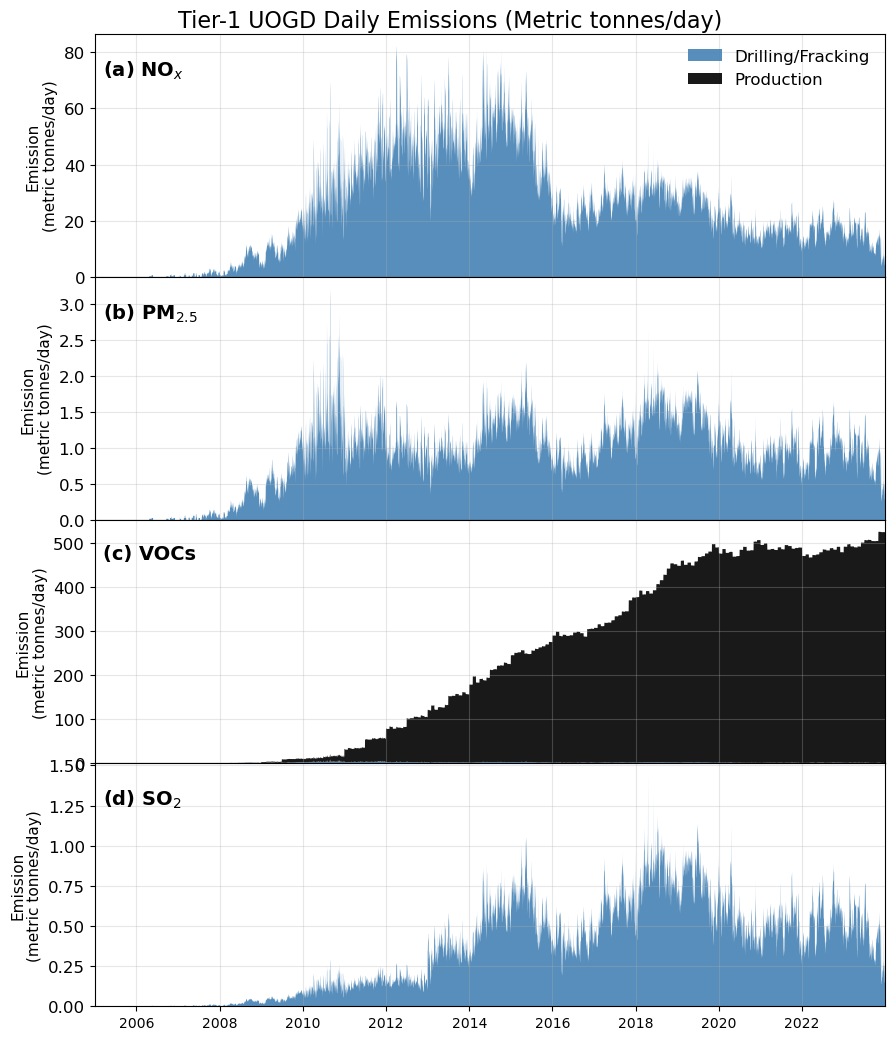

**Caption.** Figure 5. Daily Tier 1 emissions from drilling/completion and production. Emissions are metric tonnes. Production includes leakage and heaters; monthly inventories are allocated uniformly over calendar days.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_05_tier1_emissions.png


In [5]:
plot_inventory_tier(1)


## Figure 6. Tier 2 emissions

Monthly emissions from compressors and the selected other Tier 2 facilities. Values are metric tonnes/month.

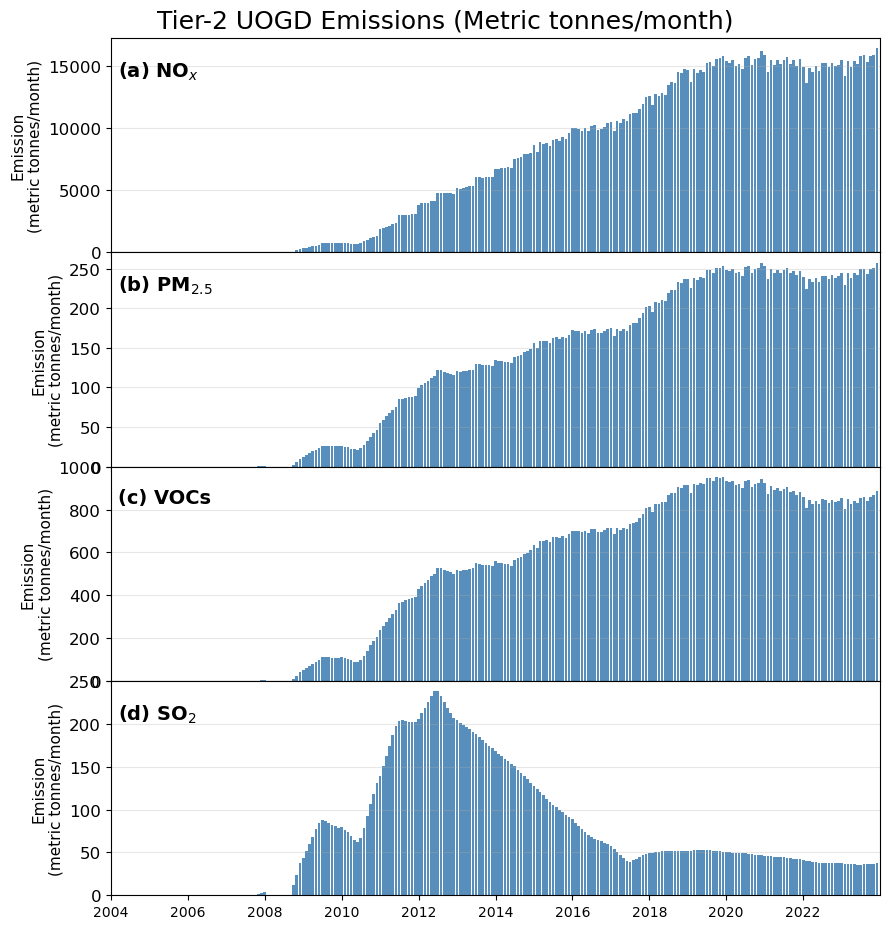

**Caption.** Figure 6. Total monthly Tier 2 emissions from compressors and other Tier 2 facilities. Emissions are metric tonnes. Production includes leakage and heaters; monthly inventories are allocated uniformly over calendar days.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_06_tier2_emissions.png


In [6]:
plot_inventory_tier(2)


## Figure 7. Regional industrial and power plant emissions

Daily power plant emissions and daily allocations of annual industrial emissions. Power plant inputs use the short-ton interpretation in the model code and are converted to metric tonnes.

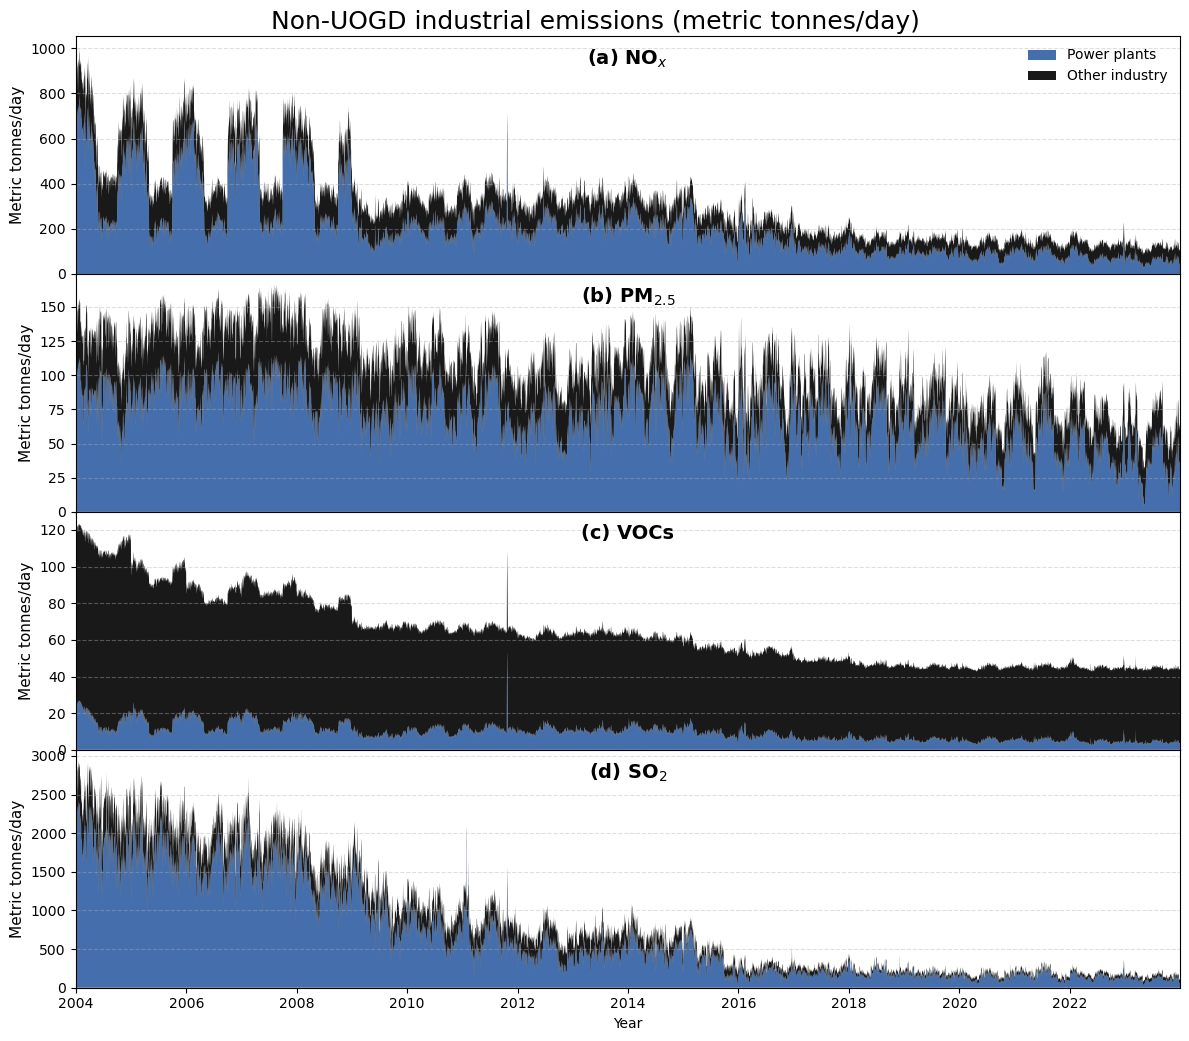

**Caption.** Figure 7. Daily power-plant emissions and uniform daily allocations of annual non-UOGD industrial emissions. Power-plant daily input values are interpreted as US short tons, consistent with the model job, and converted to metric tonnes. Industry is read in metric tonnes. These are emissions, not dispersion-model concentrations.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_07_regional_emissions.png


In [7]:
regional_emissions()


## Figure 8. Roadway emissions

Annual roadway emissions in metric tonnes. SO₂ is estimated using the BTS highway-vehicle SO₂/NOₓ mass ratio.

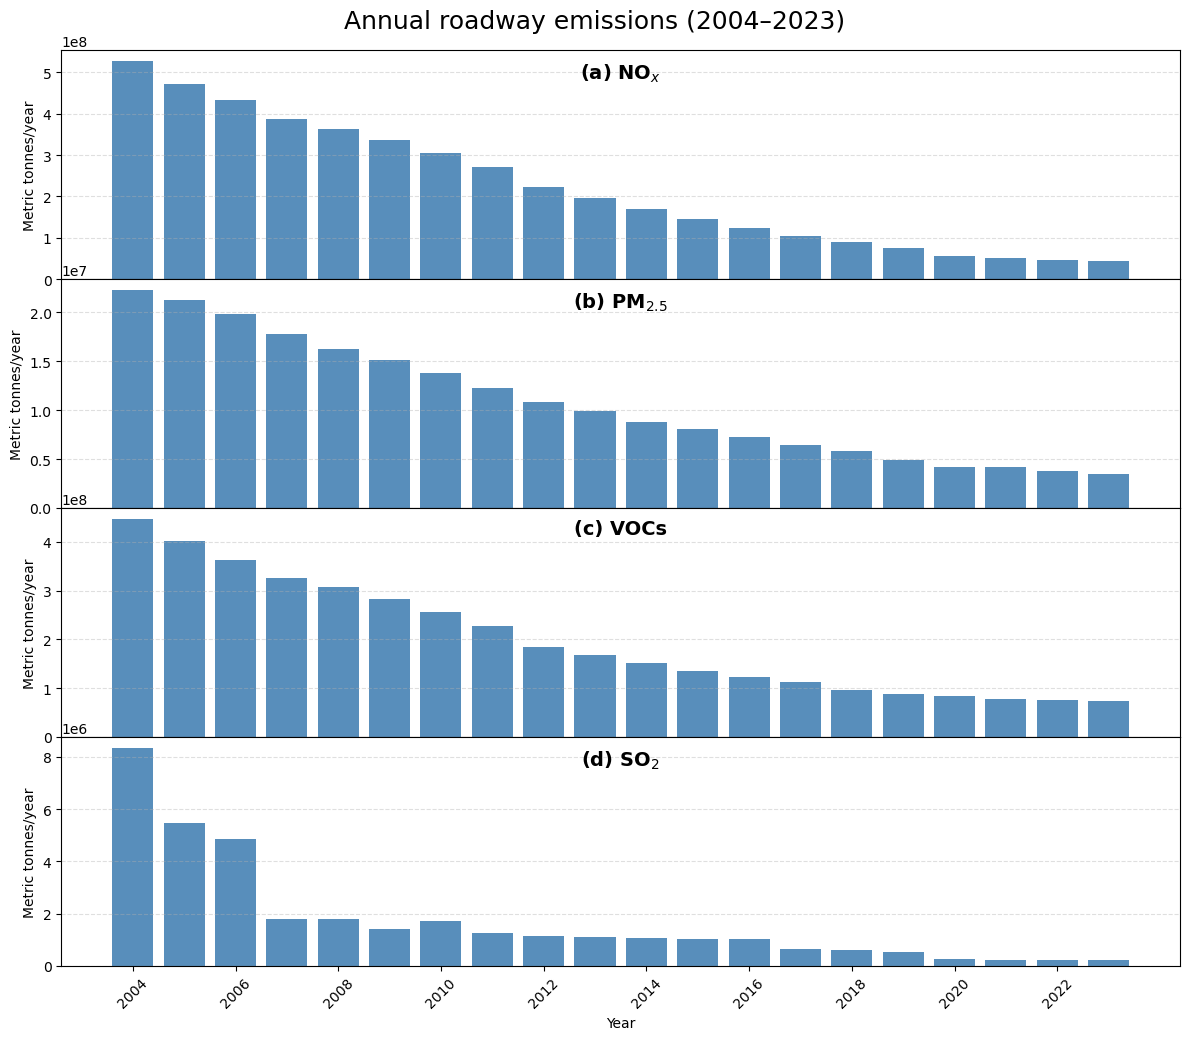

**Caption.** Figure 8. Annual roadway emissions. NOx, PM2.5 and VOC rates are integrated using each calendar year’s day count. SO2 is estimated from the BTS highway-vehicle SO2/NOx mass ratio. Values are metric tonnes/year.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_08_roadway_emissions.png


In [8]:
roadway_emissions()


## Figures 9–12. Sensitivity and validation

These figures require their own sensitivity outputs, monitoring comparisons or satellite comparison inputs. They cannot be regenerated from the combined concentration NetCDFs. They are not presented here as updated results. Add the refreshed analysis for these figures before submitting a complete report-figure notebook.

## Figure 13. Annual average NO₂ concentrations from UOGD sources

Annual means are plotted on the same logarithmic scale in every panel. Valid values below the display minimum use the deep-blue minimum colour; missing cells remain blank. County boundaries are overlaid. NO₂ and SO₂ are in ppb; PM₂.₅ and VOC are in µg/m³.

ERROR 1: PROJ: proj_create_from_database: Open of /storage/home/smd7311/.conda/envs/env_ong_sd/share/proj failed


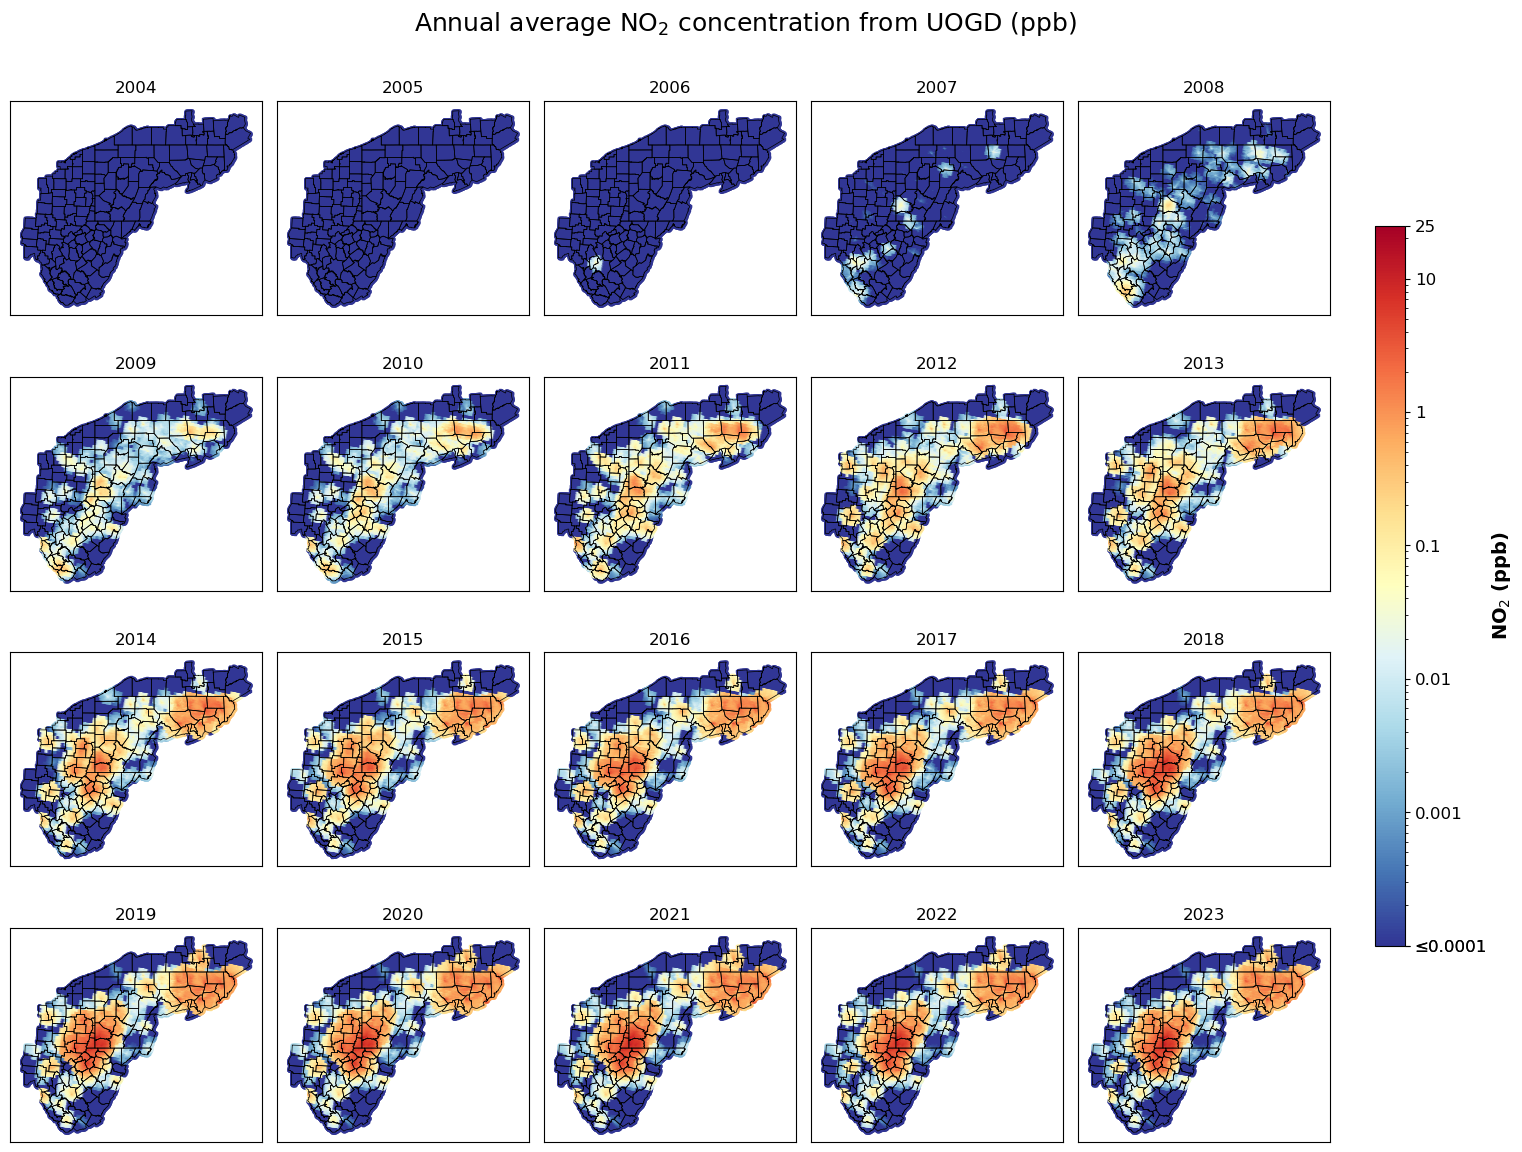

**Caption.** Figure 13. Annual mean NO2 concentrations (ppb) attributable to UOGD sources, 2004–2023. Concentrations at or below the display minimum (0.0001) use the deep-blue minimum color; flooring affects display only. Missing cells remain blank. County boundaries are overlaid. The same logarithmic color scale is used for all years. Summary statistics use the original unfloored concentrations.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_13_NO2_annual_concentration.png


In [9]:
annual_NO2_summary = annual_maps('NO2', "concentration")


## Figure 14. Annual average PM₂.₅ concentrations from UOGD sources

Annual means are plotted on the same logarithmic scale in every panel. Valid values below the display minimum use the deep-blue minimum colour; missing cells remain blank. County boundaries are overlaid. NO₂ and SO₂ are in ppb; PM₂.₅ and VOC are in µg/m³.

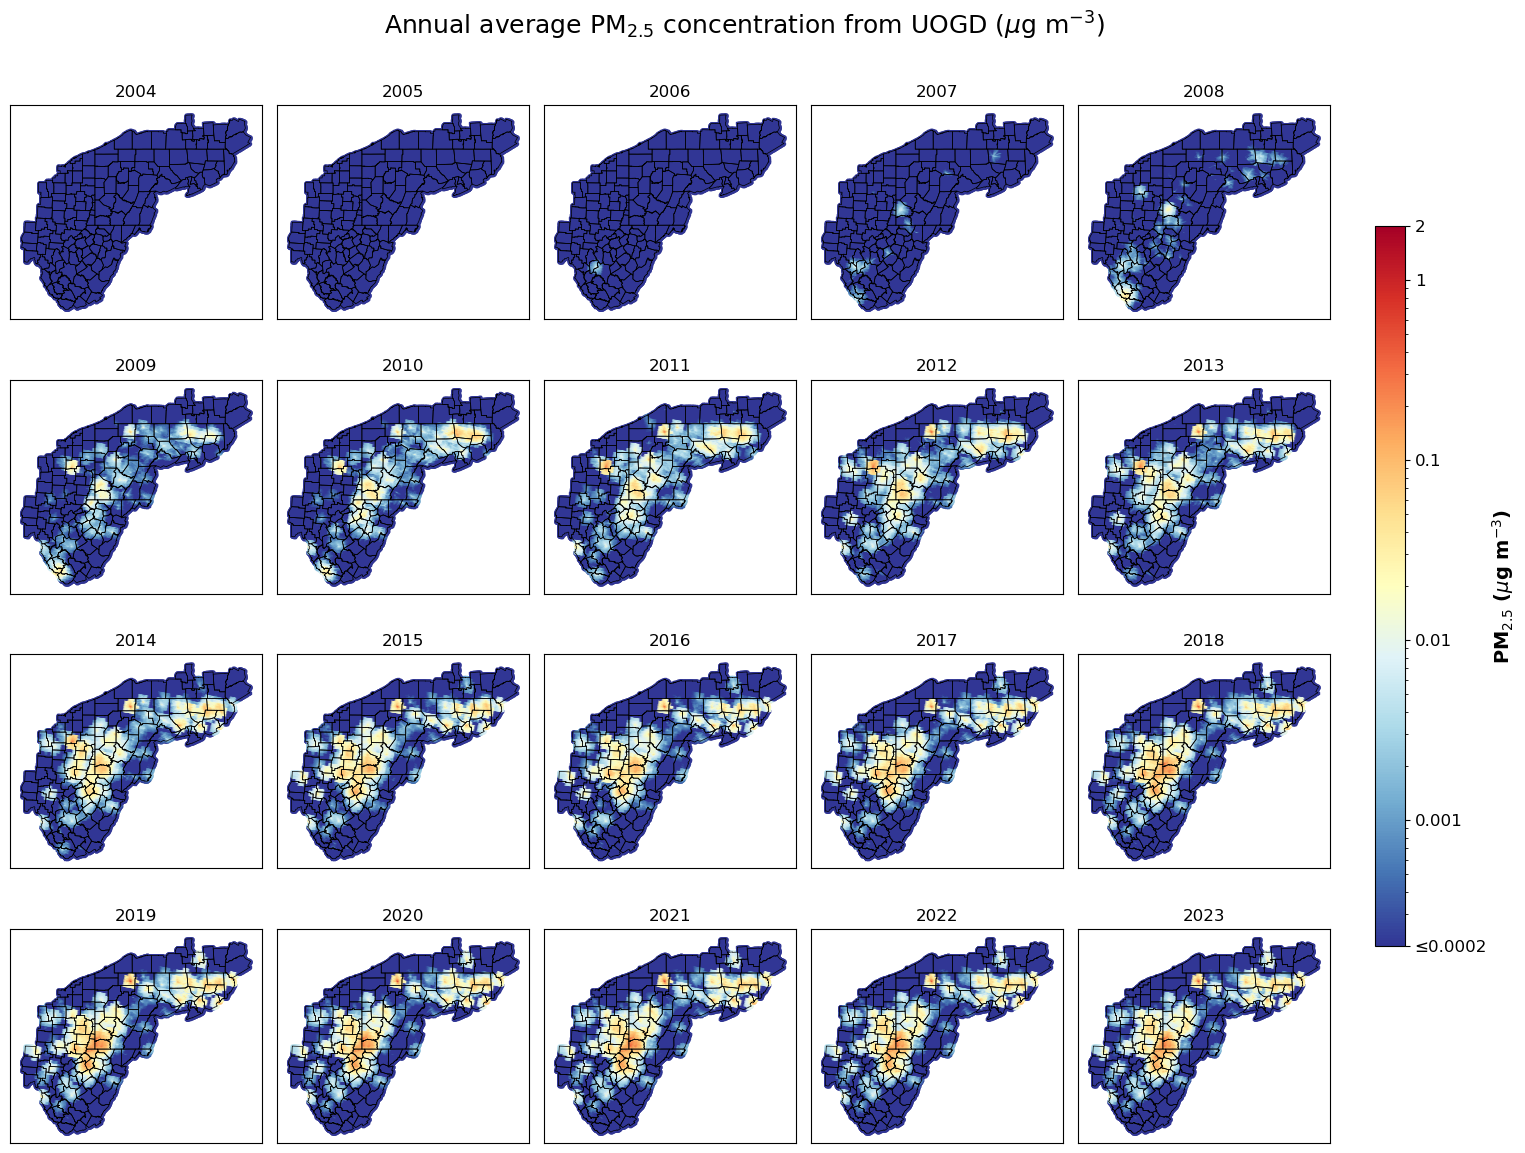

**Caption.** Figure 14. Annual mean PM25 concentrations ($\mu$g m$^{-3}$) attributable to UOGD sources, 2004–2023. Concentrations at or below the display minimum (0.0002) use the deep-blue minimum color; flooring affects display only. Missing cells remain blank. County boundaries are overlaid. The same logarithmic color scale is used for all years. Summary statistics use the original unfloored concentrations.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_14_PM25_annual_concentration.png


In [10]:
annual_PM25_summary = annual_maps('PM25', "concentration")


## Figure 15. Annual average VOC concentrations from UOGD sources

Annual means are plotted on the same logarithmic scale in every panel. Valid values below the display minimum use the deep-blue minimum colour; missing cells remain blank. County boundaries are overlaid. NO₂ and SO₂ are in ppb; PM₂.₅ and VOC are in µg/m³.

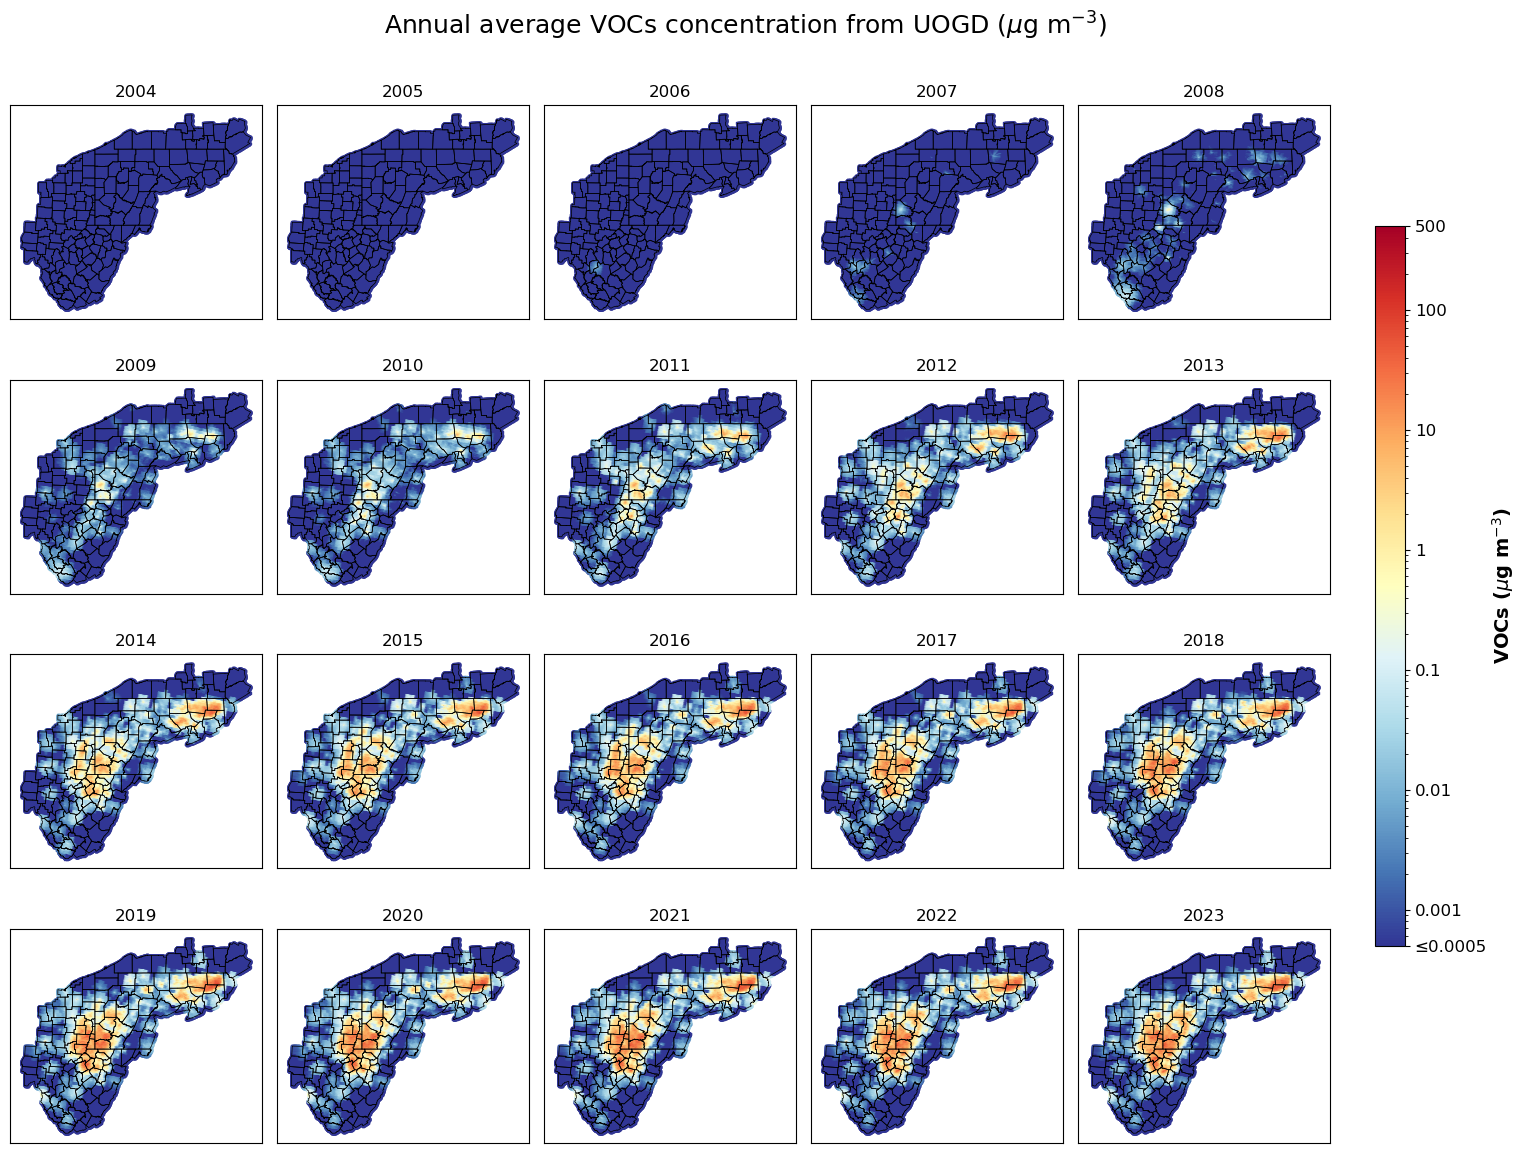

**Caption.** Figure 15. Annual mean VOC concentrations ($\mu$g m$^{-3}$) attributable to UOGD sources, 2004–2023. Concentrations at or below the display minimum (0.0005) use the deep-blue minimum color; flooring affects display only. Missing cells remain blank. County boundaries are overlaid. The same logarithmic color scale is used for all years. Summary statistics use the original unfloored concentrations.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_15_VOC_annual_concentration.png


In [11]:
annual_VOC_summary = annual_maps('VOC', "concentration")


## Figure 16. Annual average SO₂ concentrations from UOGD sources

Annual means are plotted on the same logarithmic scale in every panel. Valid values below the display minimum use the deep-blue minimum colour; missing cells remain blank. County boundaries are overlaid. NO₂ and SO₂ are in ppb; PM₂.₅ and VOC are in µg/m³.

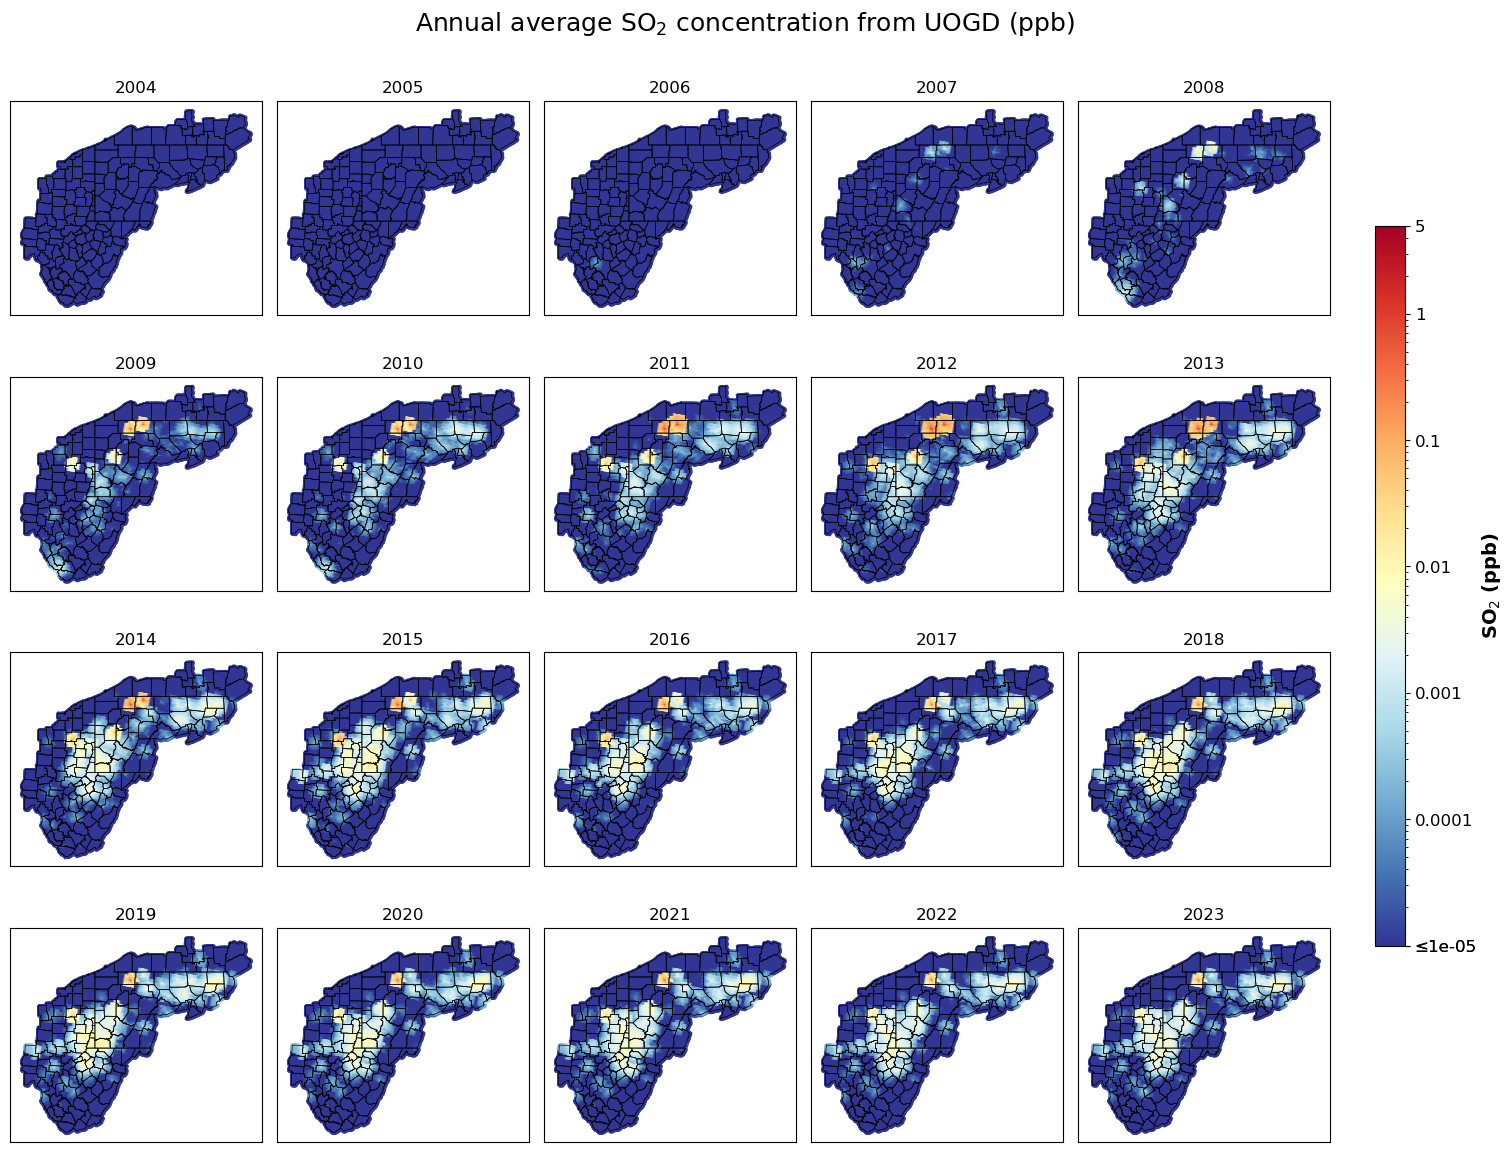

**Caption.** Figure 16. Annual mean SO2 concentrations (ppb) attributable to UOGD sources, 2004–2023. Concentrations at or below the display minimum (1e-05) use the deep-blue minimum color; flooring affects display only. Missing cells remain blank. County boundaries are overlaid. The same logarithmic color scale is used for all years. Summary statistics use the original unfloored concentrations.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_16_SO2_annual_concentration.png


In [12]:
annual_SO2_summary = annual_maps('SO2', "concentration")


## Figure 17. Daily, rolling and monthly concentration time series

Unweighted study-area daily means, with the original blue daily line, orange 30-day rolling mean and green dashed monthly mean.

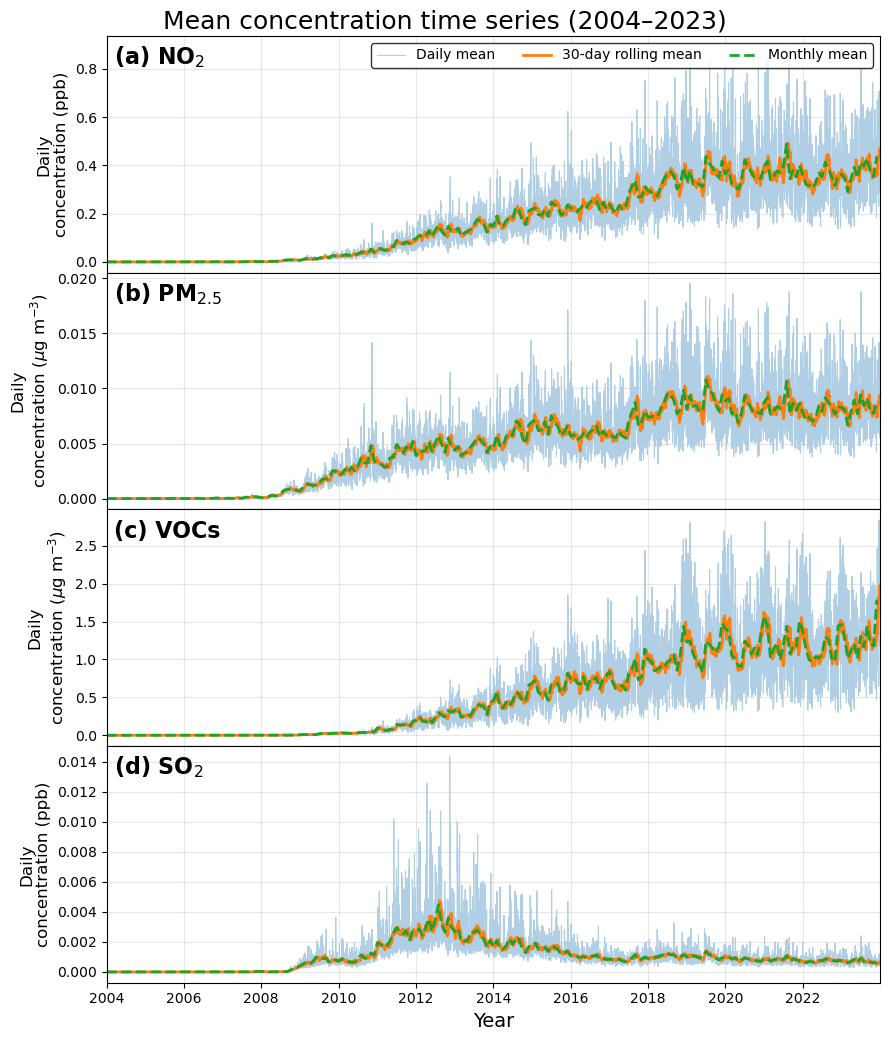

**Caption.** Figure 17. Study-area daily mean UOGD concentrations, 2004–2023. Blue: daily mean; orange: centered 30-day rolling mean; green dashed: monthly mean. NO2/SO2 are ppb and PM2.5/VOC are ug/m3. Values are spatial means, not population-weighted exposures.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_17_daily_concentration_timeseries.png


In [13]:
daily_summary = daily_spatial_summary()
time_series_figure(daily_summary)


## Figure 18. Population-weighted exposure

Annual study-area mean and population-weighted concentrations for the total population, children under five, adults aged 65 and over, and residents below twice the poverty threshold.

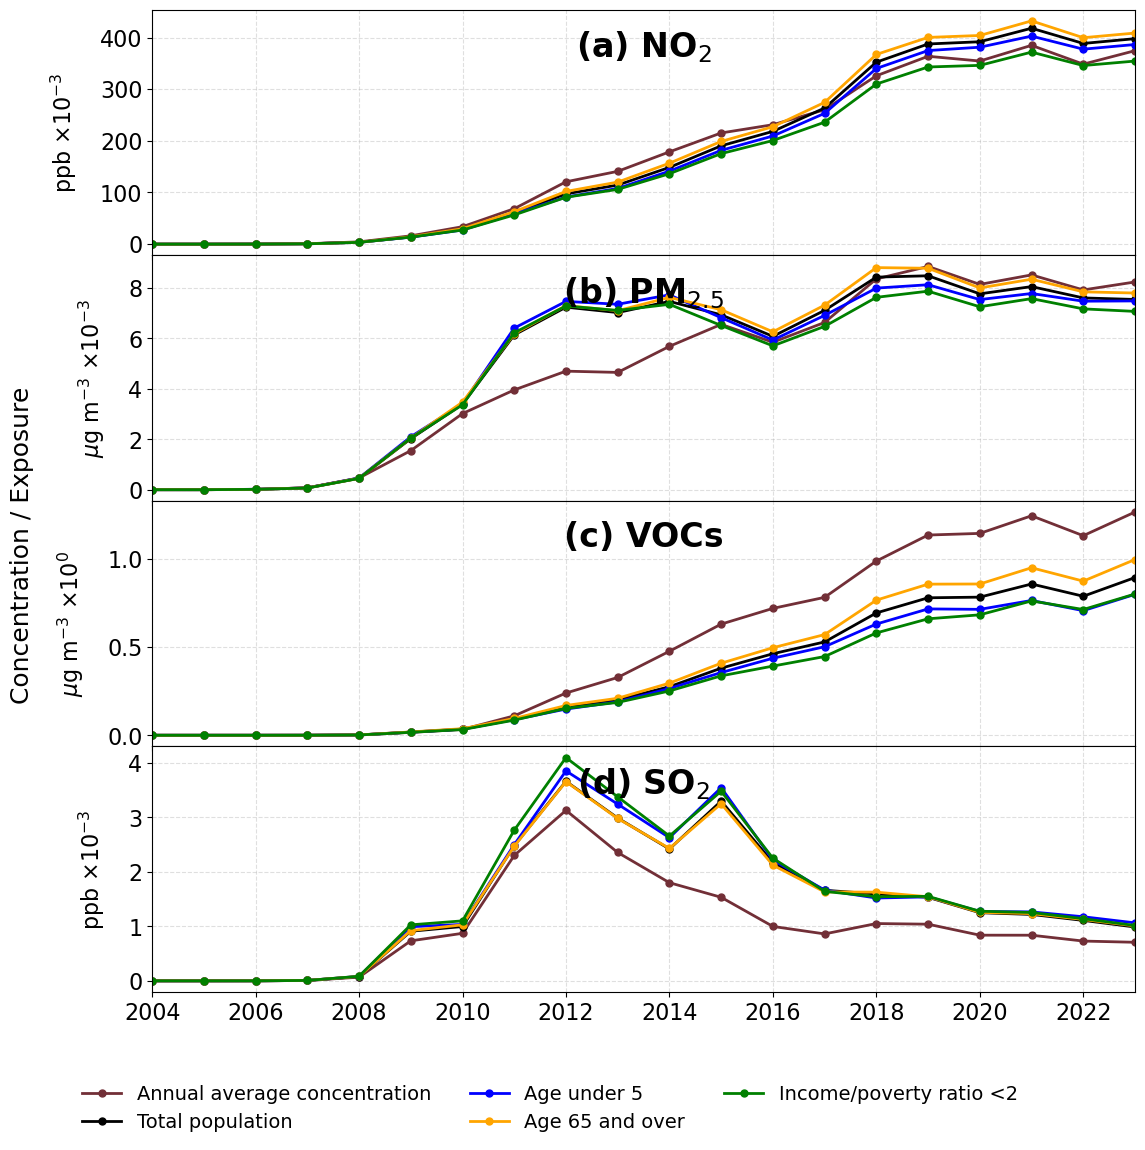

**Caption.** Figure 18. Annual UOGD spatial mean and population-weighted concentrations for the overall population, children under 5, adults over 64 and low-income residents. Calculated from the current concentrations and processed population counts. NO2/SO2 are ppb; PM2.5/VOC are ug/m3. Axis scaling is shown separately for each panel.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_18_exposure.png


In [14]:
current_exposure_figure()


## Figure 19. Population above annual concentration benchmarks

Residents in cells where annual modeled UOGD NO₂ exceeds 10 µg/m³ or PM₂.₅ exceeds 5 µg/m³. These are source-component comparisons, not measured total-ambient compliance counts.

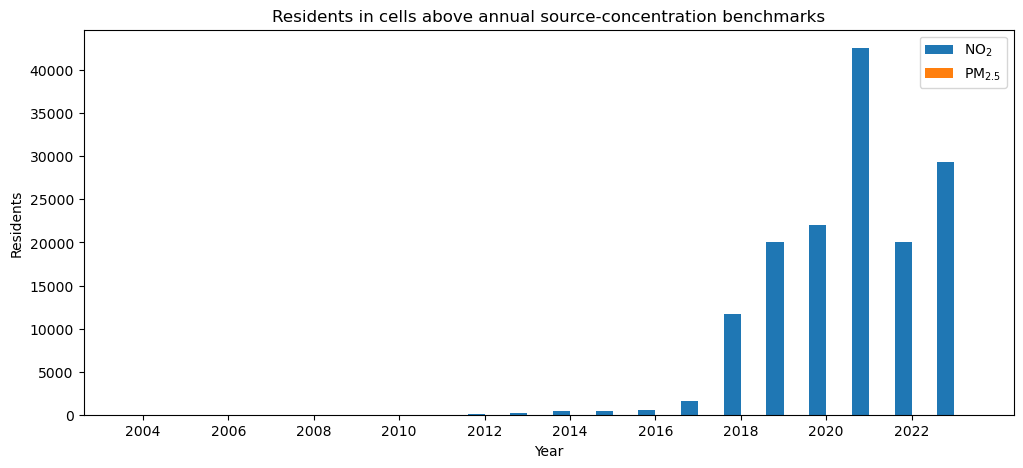

**Caption.** Figure 19. Residents in cells exceeding the annual modeled-source concentration benchmarks. These are source-only comparisons, not total ambient compliance.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_19_annual_exceedances.png


In [15]:
figure19()


## Figure 20. Population above daily concentration benchmarks

Daily residents in cells above the full daily benchmarks: NO₂ 25 µg/m³, PM₂.₅ 15 µg/m³ and SO₂ 40 µg/m³. Summing daily counts gives person-days, not unique residents.

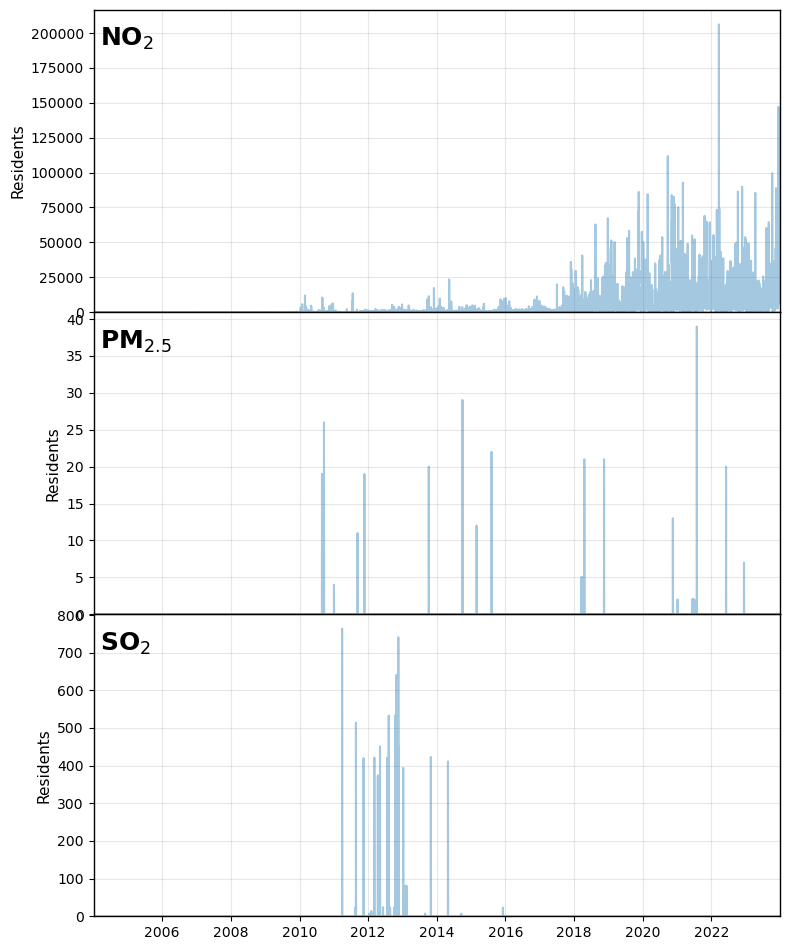

**Caption.** Figure 20. Daily residents in cells where the modeled UOGD contribution exceeds the report’s daily concentration benchmarks. Each point is a daily resident count; summing across dates gives person-days, not unique people. These are not total ambient compliance counts.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_20_daily_exceedances.png


In [16]:
figure20()


## Figure 21. Demographic ratios for annual threshold exceedances

Each group’s proportion of residents in an annual-threshold-exceeding cell relative to that proportion for the total population. Undefined years remain gaps. This is a residence ratio, not a disease-risk estimate.

Before 2012, no residents exceeded the annual NO₂ benchmark, so the relative residence ratio is undefined (0/0). These years remain blank. PM₂.₅ has no annual benchmark exceedances throughout the study. Population and concentration data are available; see the continuous annual demographic exposure-ratio supplement for a comparison that does not require exceedances.


/tmp/ipykernel_1941008/3949383772.py:320: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.04,.04,1,.97])


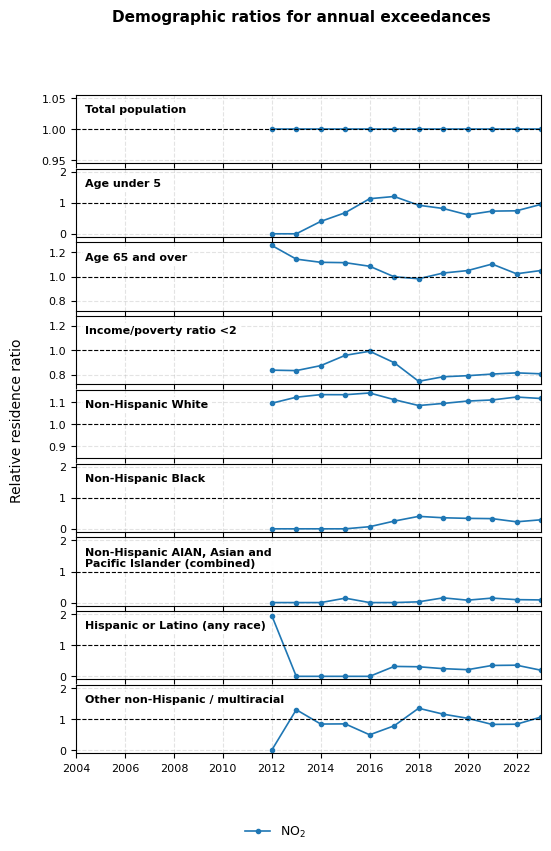

**Caption.** Figure 21. Demographic relative residence ratios for modeled-source benchmark exceedances. Undefined years remain gaps; they are not set to zero or one. The daily aggregate uses person-days. Small exposed counts can yield unstable group ratios. AIAN denotes American Indian/Alaska Native; the combined AIAN–Asian–Pacific group cannot be interpreted as Asian alone. These are residence ratios, not disease-risk estimates.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_21_annual_RRR.png


In [17]:
current_rrr_figure("annual")


## Figure 22. Demographic ratios for daily threshold exceedances

The daily aggregate uses demographic and total-population person-days. Undefined ratios remain missing. The combined non-Hispanic AIAN, Asian and Pacific Islander group retains its full label.

/tmp/ipykernel_1941008/3949383772.py:320: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.04,.04,1,.97])


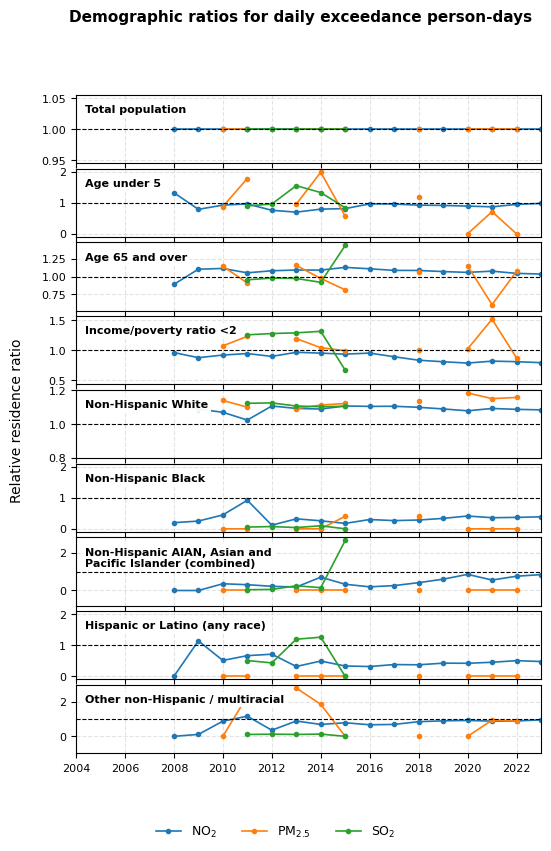

**Caption.** Figure 22. Demographic relative residence ratios for modeled-source benchmark exceedances. Undefined years remain gaps; they are not set to zero or one. The daily aggregate uses person-days. Small exposed counts can yield unstable group ratios. AIAN denotes American Indian/Alaska Native; the combined AIAN–Asian–Pacific group cannot be interpreted as Asian alone. These are residence ratios, not disease-risk estimates.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_22_daily_RRR.png


In [18]:
current_rrr_figure("daily")


## Source-contribution coverage

The minimum valid-day setting is applied only to map display. NO₂ and SO₂ have missing ML dates and cells; 2004 has partial-year coverage. The contribution variables retain those missing values.

In [19]:
coverage_table = contribution_coverage()
display(coverage_table)


,year,pollutant,source,statistic,valid_cells,mean,median,p95,p99,maximum,cells_at_or_above_one,cells_above_003,cells_above_008,cells_above_040,study_cells_no_valid_days,minimum_valid_days,median_valid_days,maximum_valid_days
2,2004,NO2,UOGD,annual_mean_fraction,214875,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0,8022,0,74.0,74
8,2004,PM2.5,UOGD,annual_mean_fraction,222897,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0,0,366,366.0,366
14,2004,SO2,UOGD,annual_mean_fraction,214875,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0,8022,0,76.0,76
20,2005,NO2,UOGD,annual_mean_fraction,214875,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0,8022,0,350.0,350
26,2005,PM2.5,UOGD,annual_mean_fraction,222897,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0,0,365,365.0,365
32,2005,SO2,UOGD,annual_mean_fraction,214875,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0,8022,0,354.0,354
38,2006,NO2,UOGD,annual_mean_fraction,214875,9.715582e-06,0.000000e+00,0.000000,0.000000,0.014577,0,0,0,0,8022,0,349.0,349
44,2006,PM2.5,UOGD,annual_mean_fraction,222897,1.000656e-06,0.000000e+00,0.000000,0.000000,0.001557,0,0,0,0,0,365,365.0,365
50,2006,SO2,UOGD,annual_mean_fraction,214875,8.370501e-08,0.000000e+00,0.000000,0.000000,0.000134,0,0,0,0,8022,0,352.0,352
56,2007,NO2,UOGD,annual_mean_fraction,214875,7.466049e-05,1.556934e-08,0.000377,0.001768,0.016664,0,0,0,0,8022,0,348.0,348


## Figure 36. UOGD / ML NO₂ concentration ratios

The primary panels retain the mean of valid daily source/ML ratios. The colour-bar extension and saved map summary identify values above the display range. Ratios above one remain in the data; these independent model comparisons are not constrained pollution-budget shares.

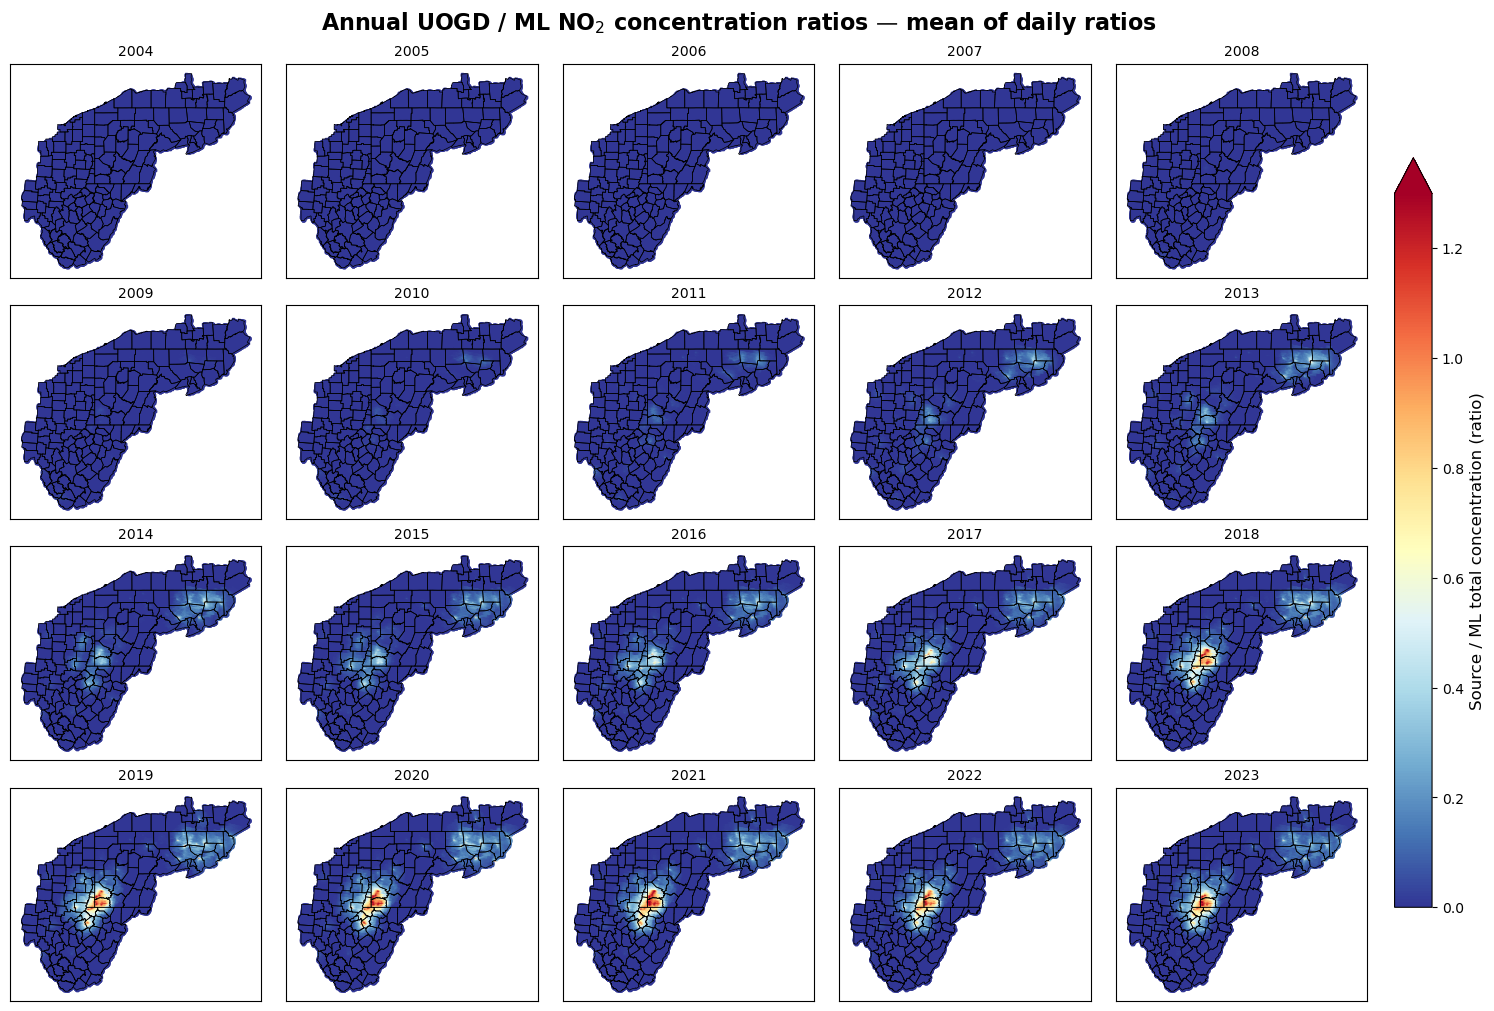

**Caption.** Figure 36. Annual UOGD contribution to ML-predicted total NO2, 2004–2023, expressed as a fraction. Annual values are the mean of valid daily concentration ratios. County boundaries are overlaid. The common display range is 0–1.3; values above the upper limit use the maximum color. Missing values remain blank, and ratios above one are retained in the data. At least 1 valid day(s) are required. The largest original value across panels is 5970.68; 1083 cell-year values exceed the display maximum. These source/ML comparisons are not constrained to a physical percentage between zero and one.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_36_NO2_annual_mean_fraction.png


In [33]:
contribution_NO2_summary = annual_maps('NO2', "contribution")


## Figure 37. UOGD / ML PM₂.₅ concentration ratios

The primary panels retain the mean of valid daily source/ML ratios. The colour-bar extension and saved map summary identify values above the display range. Ratios above one remain in the data; these independent model comparisons are not constrained pollution-budget shares.

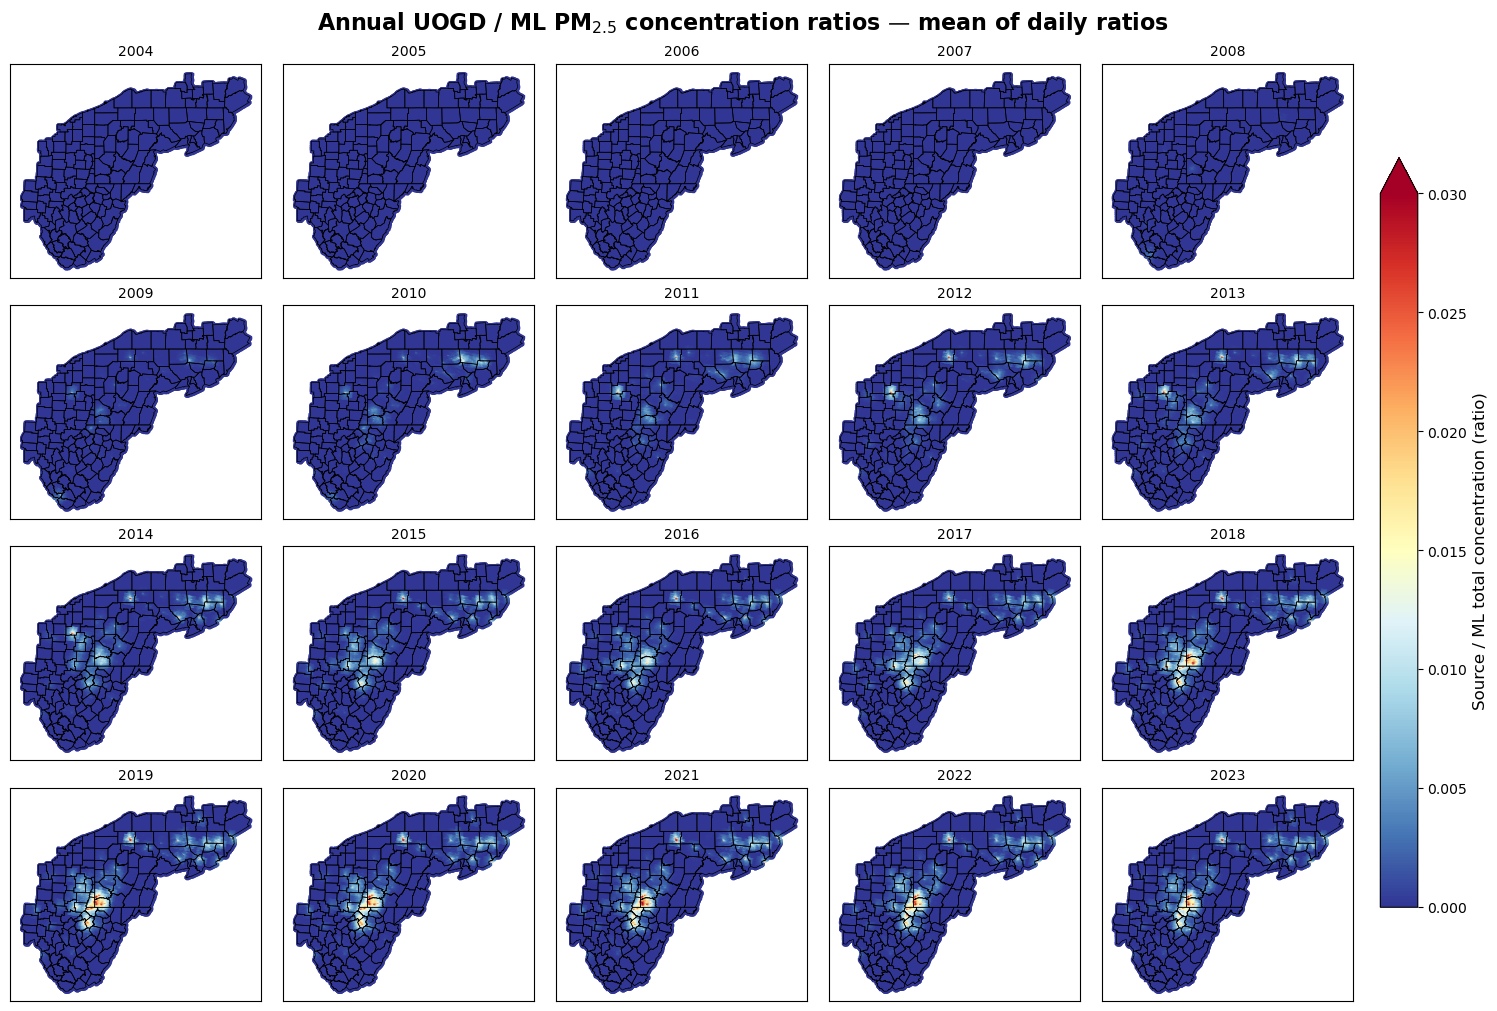

**Caption.** Figure 37. Annual UOGD contribution to ML-predicted total PM25, 2004–2023, expressed as a fraction. Annual values are the mean of valid daily concentration ratios. County boundaries are overlaid. The common display range is 0–0.03; values above the upper limit use the maximum color. Missing values remain blank, and ratios above one are retained in the data. At least 1 valid day(s) are required. The largest original value across panels is 0.176384; 1072 cell-year values exceed the display maximum. These source/ML comparisons are not constrained to a physical percentage between zero and one.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_37_PM25_annual_mean_fraction.png


In [21]:
contribution_PM25_summary = annual_maps('PM25', "contribution")


## Figure 38. UOGD / ML SO₂ concentration ratios

The primary panels retain the mean of valid daily source/ML ratios. The colour-bar extension and saved map summary identify values above the display range. Ratios above one remain in the data; these independent model comparisons are not constrained pollution-budget shares.

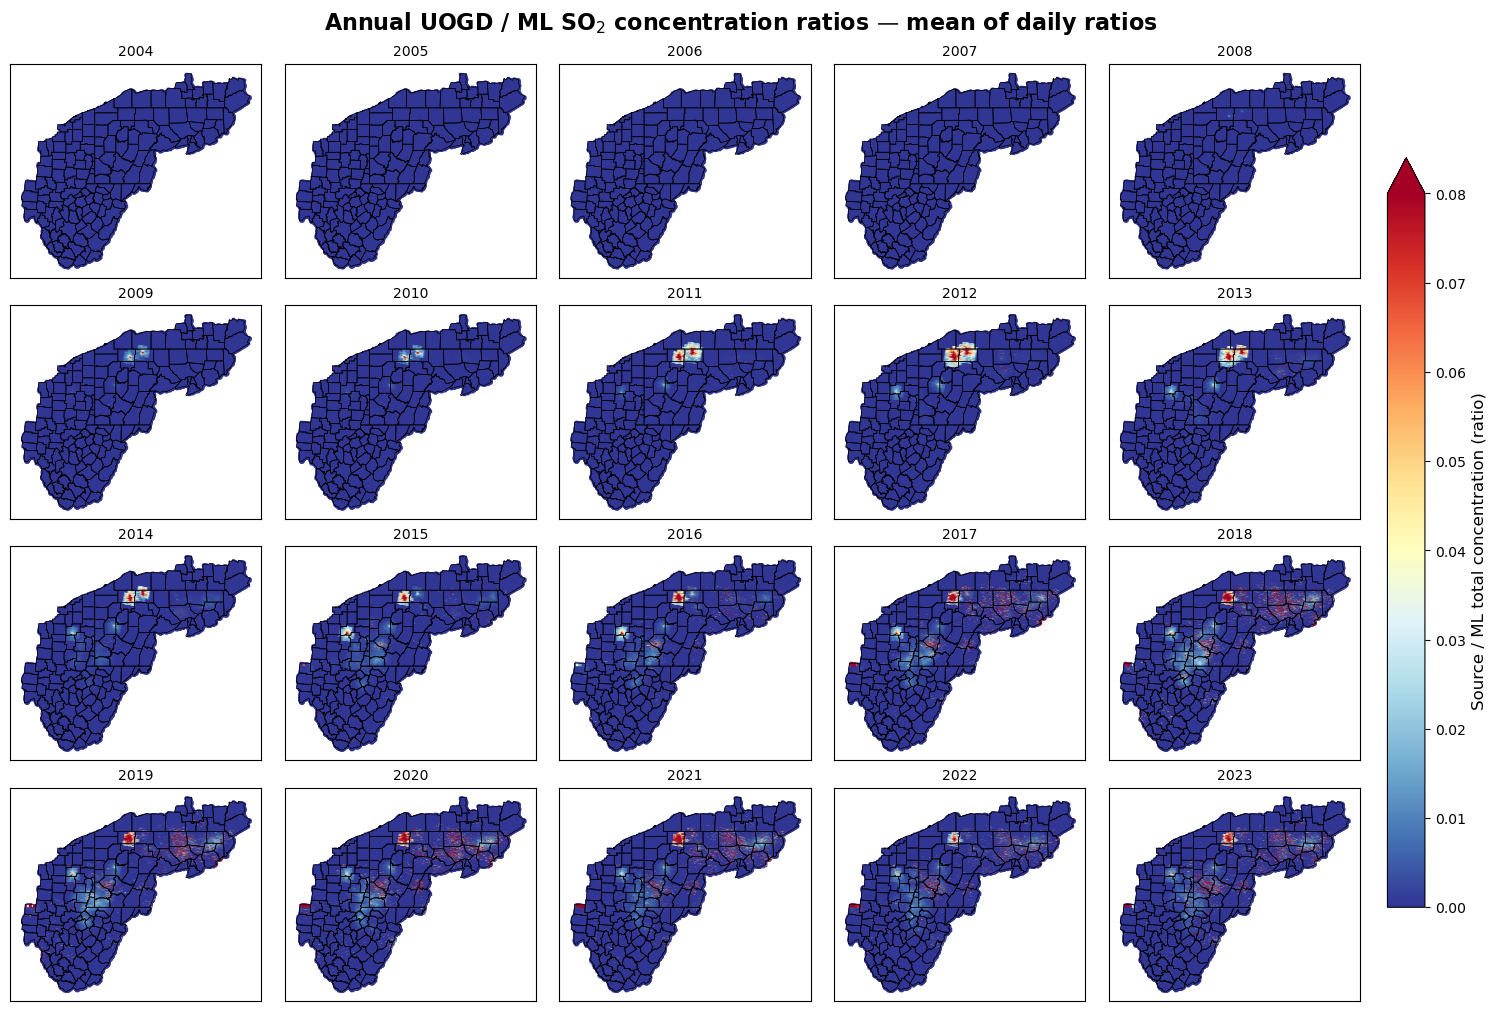

**Caption.** Figure 38. Annual UOGD contribution to ML-predicted total SO2, 2004–2023, expressed as a fraction. Annual values are the mean of valid daily concentration ratios. County boundaries are overlaid. The common display range is 0–0.08; values above the upper limit use the maximum color. Missing values remain blank, and ratios above one are retained in the data. At least 1 valid day(s) are required. The largest original value across panels is 736029; 51273 cell-year values exceed the display maximum. These source/ML comparisons are not constrained to a physical percentage between zero and one.

Saved: /storage/home/smd7311/scratch/TriMAQs_AERMOD_full_calculation/processed/figures/report_current/Figure_38_SO2_annual_mean_fraction.png


In [22]:
contribution_SO2_summary = annual_maps('SO2', "contribution")


## Save the figure index and captions

Run this final cell after plotting. Save the executed notebook to retain the inline figures for GitHub preview. High-resolution PNGs, captions and data tables remain in `FIGURE_DIR`.

In [ ]:
save_figure_records()
display(pd.DataFrame(FIGURE_RECORDS))
